# Analyse exploratoire des données — Adult Income (UCI)

**Objectif du dataset :** prédire si le revenu annuel d'un individu dépasse
50 000 \$ (`>50K`) ou non (`<=50K`) à partir de caractéristiques
socio-démographiques (recensement US de 1994).

Ce notebook réalise une **EDA complète** en s'appuyant sur le module
`adult_income.eda.EDAAnalyzer`. Chaque section comporte :

> ⚠️ Bonne pratique : l'EDA se fait idéalement sur le **jeu d'entraînement
> uniquement**, pour ne pas « espionner » le test set (data leakage).
> Ici on explore l'ensemble complet pour décrire la donnée, mais on garde ce
> principe en tête au moment de modéliser.

## 0. Préparation de l'environnement

In [1]:
# Recharge automatique des modules src/ modifiés sans restart du kernel
%load_ext autoreload
%autoreload 2

# Permet d'importer le package src/ depuis le dossier notebooks/
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from adult_income import (
    DataLoader,
    EDAAnalyzer,
    CATEGORICAL_FEATURES,
    NUMERICAL_FEATURES,
    TARGET,
    POSITIVE_CLASS,
    NEGATIVE_CLASS,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Imports OK")

Imports OK


## 1. Chargement des données

In [2]:
loader = DataLoader(test_size=0.2, random_state=42)
X, y = loader.load()

eda = EDAAnalyzer(X, y)
df = eda.df  # X + colonne cible 'income', pratique pour les croisements

print(f"Observations : {X.shape[0]:,}")
print(f"Features     : {X.shape[1]}")
df.head()

Observations : 48,842
Features     : 14


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



On a donc 48842 observations, ce qui est assez conséquent et qui nous évite les problématiques liées à des datasets de taille réduite.
Concernant le nombre de features qui est de 14, il n'est pas trop important (nb features > nb data) ce qui nous évite aussi certaines problématiques liées à la modélisation dans des datasets trop complexes (overfitting notamment) et donc d'avoir à procéder à de la réduction de dimensions.

En revanche, particularité du dataset, les données manquantes d'une partie du dataset semblent être désignées avec des "?" (et pas des NaN), tandis que la suite du dataset (à partir de 32565) contient des NaN normaux. Pour éviter de les gérer séparément alors que "?" et NaN veulent dire la même chose, nous avons fait le choix de transformer les "?" en NaN dès le load.

De plus, les modalités de la cible se terminent par un point (`<=50K.` et `>50K.`). Nous les supprimons également dès le load pour éviter des potentielles erreurs.

In [3]:
df[df.eq('?').any(axis=1)]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income


## 2. Aperçu global & types de colonnes

In [4]:
print("=== Dimensions ===")
print("sans target :", eda.shape())
print("avec target : ", df.shape)

print("\n=== Types & mémoire ===")
df.info()

=== Dimensions ===
sans target : (48842, 14)
avec target :  (48842, 15)

=== Types & mémoire ===
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [5]:
eda.variable_overview()

,Variable,Description,Rôle,Type pandas,Type ML,Nombre de modalités
0,age,Âge de l'individu,Variable explicative,int64,Numérique,
1,workclass,Type d'employeur ou statut professionnel,Variable explicative,str,Catégorielle,8
2,fnlwgt,Poids statistique attribué à l'individu dans l...,Variable explicative,int64,Numérique,
3,education,Niveau d'éducation sous forme catégorielle,Variable explicative,str,Catégorielle,16
4,education-num,Niveau d'éducation sous forme numérique,Variable explicative,int64,Numérique,
5,marital-status,Statut marital de l'individu,Variable explicative,str,Catégorielle,7
6,occupation,Profession exercée,Variable explicative,str,Catégorielle,14
7,relationship,Lien familial ou statut dans le ménage,Variable explicative,str,Catégorielle,6
8,race,Catégorie ethnique déclarée,Variable explicative,str,Catégorielle,5
9,sex,Sexe de l'individu,Variable explicative,str,Catégorielle,2


**Observations**
Le jeu de données contient 15 variables : 14 variables explicatives et une variable cible, `income`.

Les variables explicatives sont de deux types : numériques et catégorielles. Les variables numériques décrivent par exemple l’âge, le nombre d’années d’éducation, les gains en capital ou le nombre d’heures travaillées par semaine. Les variables catégorielles décrivent notamment la situation professionnelle, le niveau d’éducation, le statut marital, la profession, le sexe ou le pays d’origine.

La variable cible `income` est une variable catégorielle binaire indiquant si le revenu annuel est inférieur ou égal à 50K ou supérieur à 50K. On travaille donc sur un problème de **classification**

Cette distinction est importante car les traitements appliqués ne seront pas les mêmes : les variables numériques pourront être standardisées, tandis que les variables catégorielles devront être encodées.

In [6]:
# Lignes strictement dupliquées (peuvent biaiser entraînement et CV)
n_dup = df.duplicated().sum()
print(f"Lignes dupliquées : {n_dup} ({n_dup / len(df) * 100:.2f} %)")

Lignes dupliquées : 52 (0.11 %)


On observe qu'il y a très peu de lignes strictement dupliquées, il y a donc peut d'intérêt à les traiter. De plus, ce ne sont pas forcément des doublons, car le dataset correspond à une enquête sans identifiant unique, donc avec un peu de chance, deux personnes peuvent avoir les mêmes caractéristiques selon l'enquête.

## 3. Variable cible & déséquilibre de classes

,count,pct
income,,
<=50K,37155,76.071823
>50K,11687,23.928177


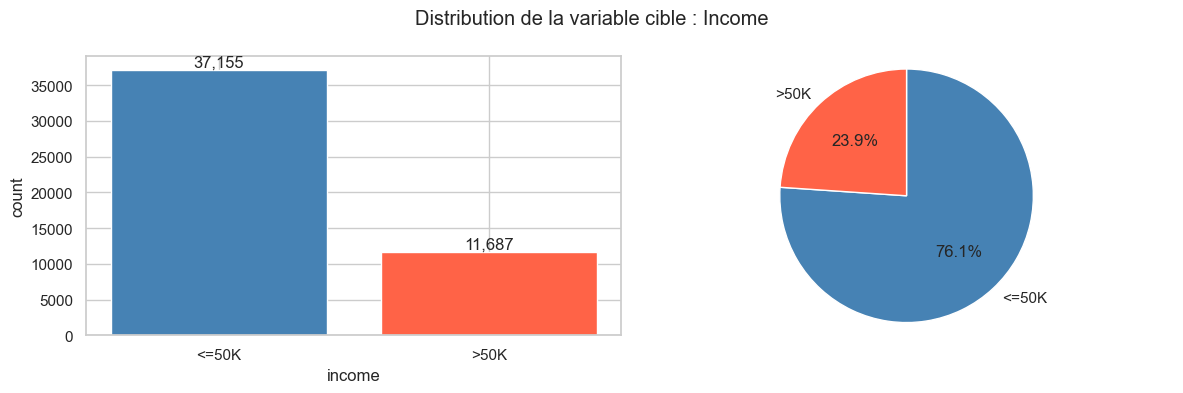

In [7]:
display(eda.class_balance())
eda.plot_class_balance()
plt.show()


La classe positive `>50K` est minoritaire (~24 %). Le dataset est donc déséquilibré (ratio ≈ 1:3).
Conséquences pour la modélisation :
  - L'accuracy seule n'est pas une bonne métrique pour ce jeu de données (un modèle prédisant toujours `<=50K`
    atteint ~76 %). Le déséquilibre restant modéré, on pourra utiliser des métriques telles que ROC-AUC, PR-AUC (souvent plus adapté en cas de déséquilibre), F1, precision/recall sur la classe positive.
  - Envisager `class_weight="balanced"`, un ré-échantillonnage, ou un ajustement
    du seuil de décision.
  - Stratifier le split train/test (déjà fait dans `DataLoader.split`) et la
    cross-validation pour préserver ce ratio.

## 4. Valeurs manquantes

Occurrences de '?' par colonne :
Aucune

NaN détectés par EDAAnalyzer.missing_values() :


,count,pct
occupation,2809,5.751198
workclass,2799,5.730724
native-country,857,1.754637


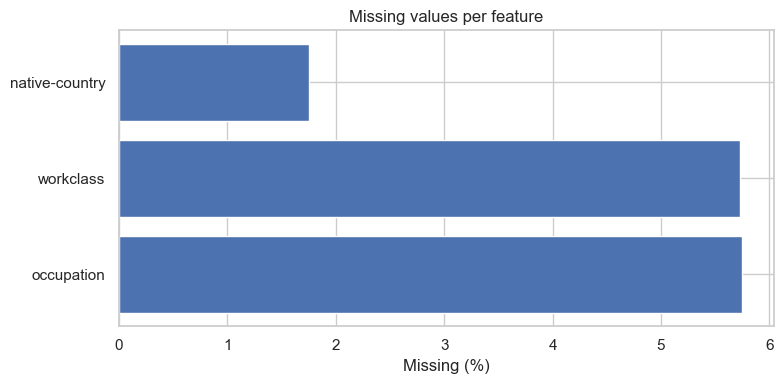

In [8]:
# Le dataset Adult code certains manquants par '?' plutôt que NaN.
q_marks = (X.astype("object") == "?").sum()
q_marks = q_marks[q_marks > 0]
print("Occurrences de '?' par colonne :")
print(q_marks if not q_marks.empty else "Aucune")

print("\nNaN détectés par EDAAnalyzer.missing_values() :")
display(eda.missing_values())

eda.plot_missing_values()
plt.show()

Les valeurs manquantes concernent uniquement certaines variables catégorielles : `occupation`, `workclass` et `native_country`. 
Comme le pourcentage de valeurs manquantes reste limité, nous conservons ces variables et nous les traiterons par exemple par imputation lors du prétraitement.

## 5. Analyse univariée

### 5.1. Variables numériques

On étudie maintenant les distributions des variables numériques.  
Cela permet d’identifier les ordres de grandeur, les asymétries, les valeurs extrêmes et les éventuelles différences d’échelle.

In [9]:
eda.numerical_stats()

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0



A part pour les feature capital-gain et capital-loss les moyennes et médianes sont très proches. Pour ces 2 features cela montre une distribution plutot asymétrique vers le haut (Tout le monde a zéro sauf quelques lignes avec des valeurs "importantes")

On peut observer des valeurs potentiellement abberantes pour la feature hours-per-weeks avec 1h et 99h, aussi la valeur max de capital gain est également très éloignée de la moyenne 99999 contre 1080. Ce sentiment est renforcé par la différence importante entre la moyenne et l'écart type pour ces 2 features.


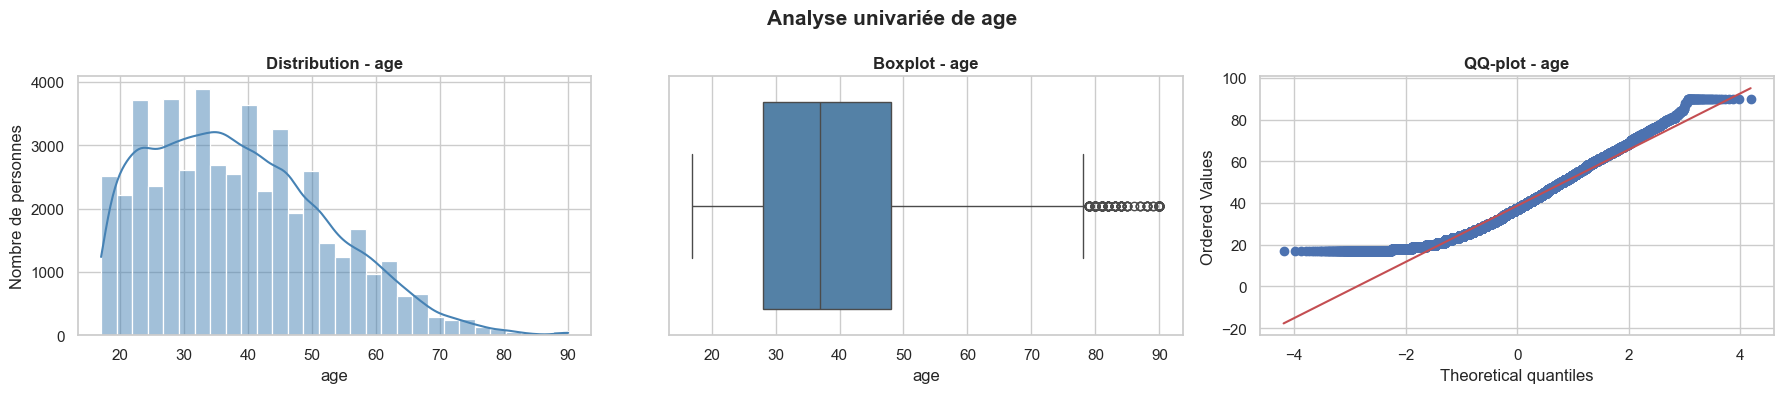

age : skewness = 0.56 | kurtosis = -0.18


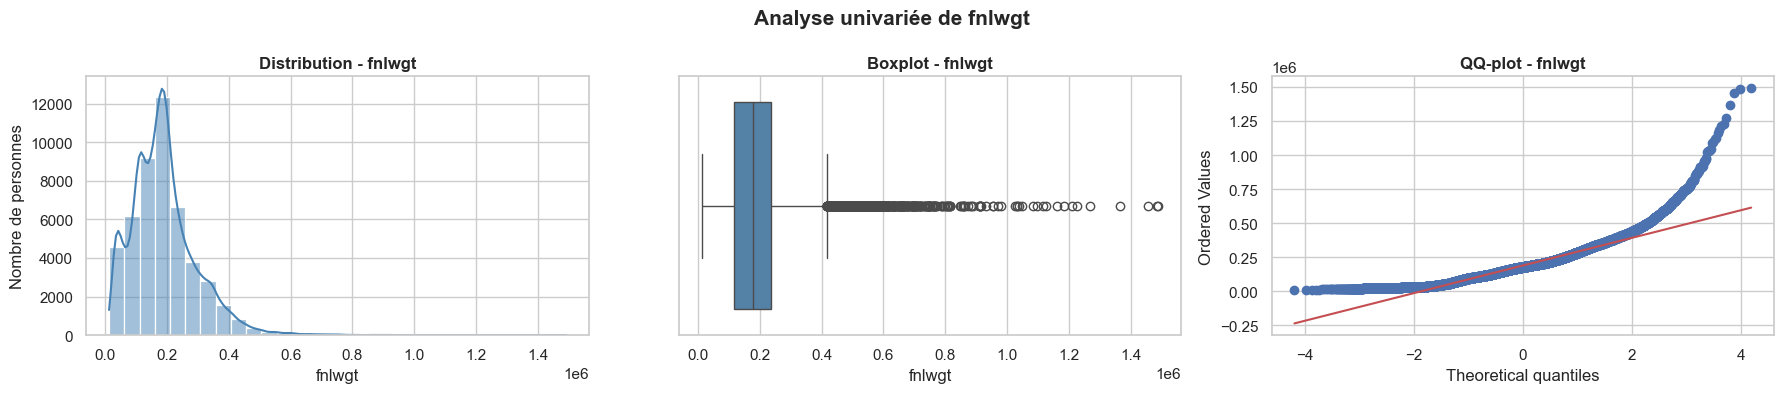

fnlwgt : skewness = 1.44 | kurtosis = 6.06


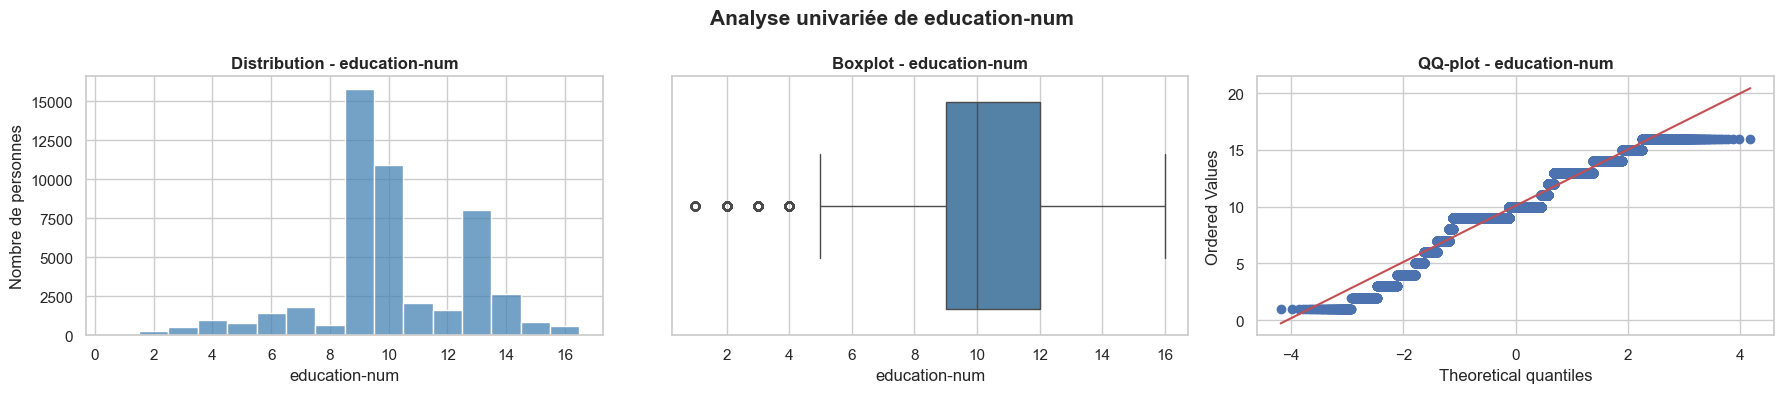

education-num : skewness = -0.32 | kurtosis = 0.63


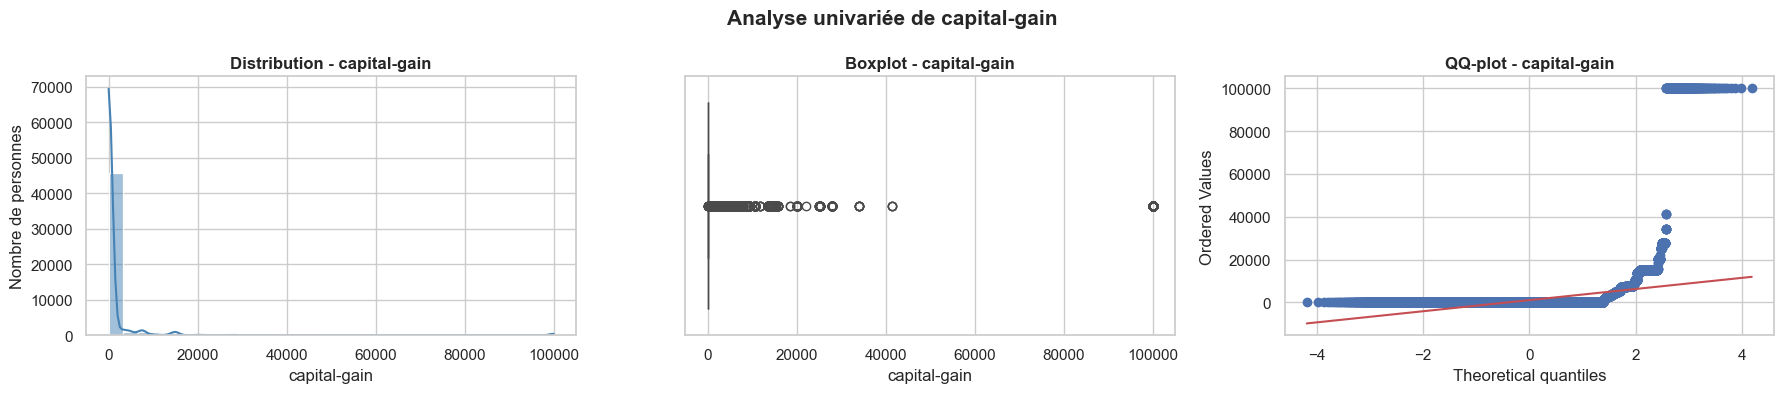

capital-gain : skewness = 11.89 | kurtosis = 152.69


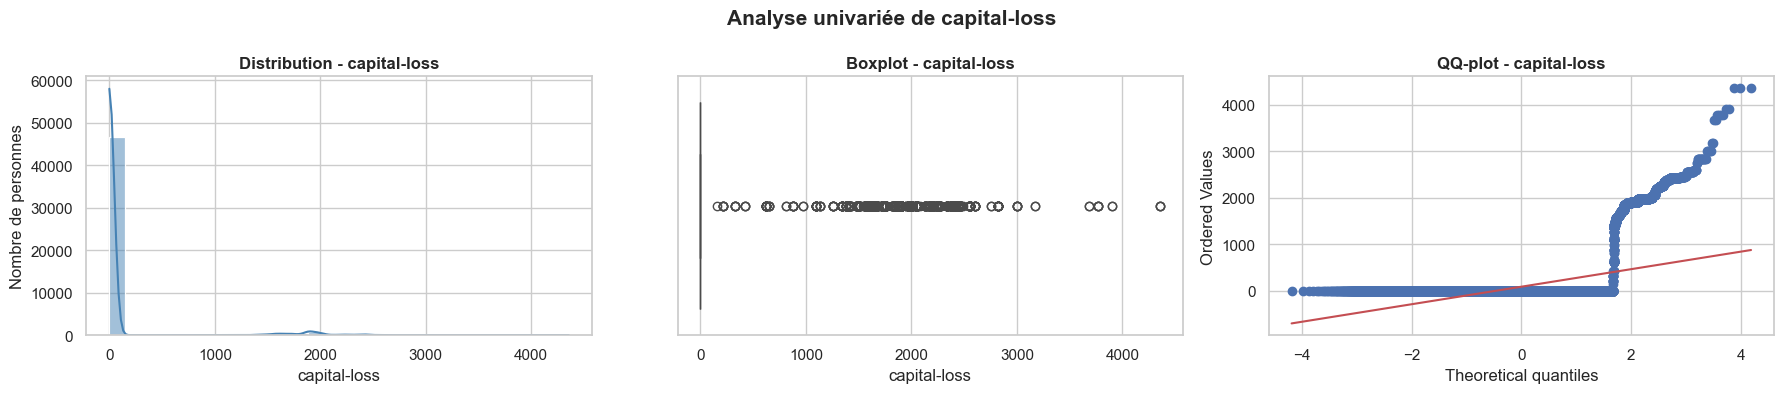

capital-loss : skewness = 4.57 | kurtosis = 20.01


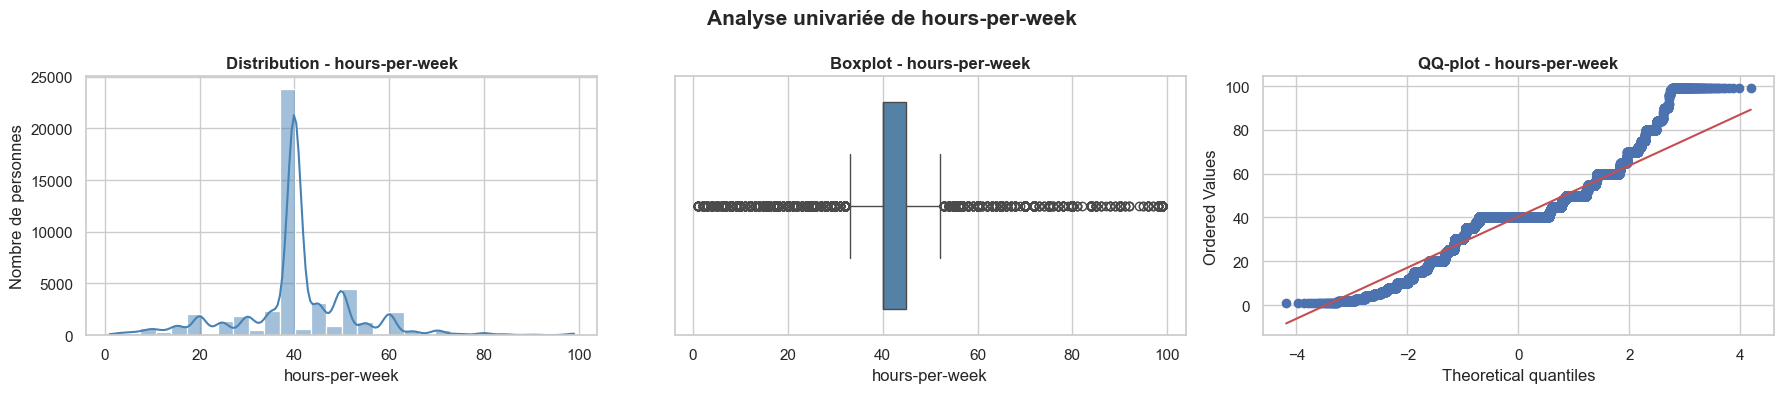

hours-per-week : skewness = 0.24 | kurtosis = 2.95


In [10]:
for i in NUMERICAL_FEATURES:
    eda.plot_numerical_univariate(i)
    plt.show()
    print(f"{i} : skewness = {eda.df[i].skew():.2f} | "f"kurtosis = {eda.df[i].kurt():.2f}")

**Observations**

Les variables numériques présentent des distributions assez différentes.

* **Âge** : la majorité des individus a entre 20 et 50 ans. La distribution est légèrement décalée vers les âges élevés. Les personnes les plus âgées apparaissent comme des valeurs aberrantes dans le boxplot, mais elles restent possibles (pas d'âges négatifs ou trop élevés). D'ordinaire, l'age forme plutot une loi normale, mais étant donné que les personnes sondées ont au minimum 17, il manque une partie significative de la queue gauche de la loi normale, ce qui fait que le Q-Q plot n'annonce pas vraiment une potentielle loi normale.

* **Poids statistique d'un individu (`fnlwgt`)** : la distribution est assez asymétrique positivement (comme le montre la skewness), avec un certain nombre de valeurs aberrantes. Le kurtosis est également élevé, ce qui donne une distribution leptokurtique (étirée). Les valeurs élevées ne sont donc pas nécessairement des erreurs, cela signifie surtout qu'ils ont un poids statistique très important, et donc qu'ils sont plus représentatifs de la population que l'individu moyen. Cette variable est assez obscure en termes de signification, et également assez subjective.

* **Années d’éducation (`education_num`)** : cette variable est discrète et présente plusieurs valeurs fréquentes, notamment entre 9 et 12 années. La forme en escalier du QQ-plot est liée au faible nombre de valeurs possibles.

* **Gain en capital (`capital-gain`)** : le fait que la grande majorité des individus possède une valeur nulle donne une forme assez difficile à lire aux graphiques en question. Nous étudierons les valeurs non nulles ci-dessous. On observe également que la skewness de 11.89 indique une distribution fortement assymétrique positivement. Le kurtosis extrêmement élevé illustre bien ce qu'on voit dans le graphique : une distribution très étirée en forme de pointe.

* **Perte en capital (`capital-loss`)** : comme pour le gain en capital, la grande majorité des valeurs est nulle et les graphiques sont assez peu informatifs. Nous étudierons plus en détail cet aspect ci-dessous. Pour le kurtosis et la skewness, le raisonnement est le même que pour `capital-gain` en légèrement moins elevé.

* **Heures travaillées par semaine (`hours-per-week`)** : la distribution présente un pic très important autour de 40 heures par semaine. Certaines personnes déclarent travailler beaucoup moins ou beaucoup plus, ce qui explique les valeurs atypiques du boxplot.

Globalement, les variables numériques ne suivent pas une loi normale et présentent des échelles très différentes. Cependant, la normalité des variables n’est pas obligatoire pour les modèles utilisés dans ce projet.

Nous conservons donc toutes les observations et toutes les variables numériques pour le moment, en gardant en tête l'aspect assez particulier de la variable `fnlwgt`.


#### 5.1.1. Analyse des variales capital-gain et capital-loss sans les valeurs nulles

In [11]:
print(eda.zero_proportion(["capital-gain", "capital-loss"]))

                    = 0       > 0
capital-gain  91.738668  8.261332
capital-loss  95.327792  4.672208


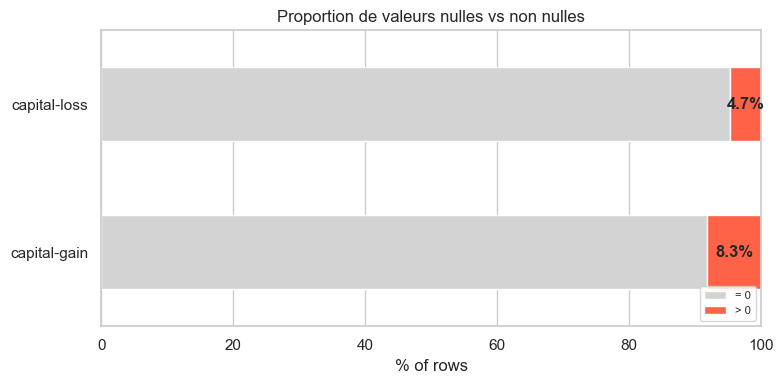

In [12]:
eda.plot_zero_proportion(["capital-gain", "capital-loss"]);

On constate bien que la proportion d'individus ayant un `capital-gain` ou un `capital-loss` > 0 est faible

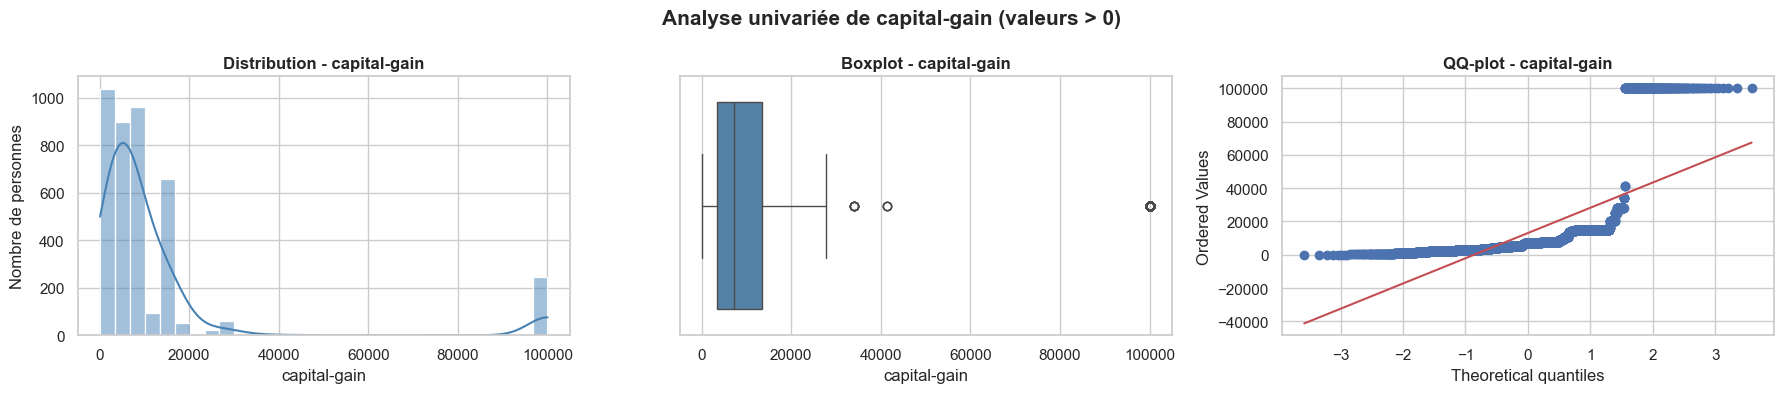

capital-gain (valeurs > 0) : skewness = 3.36 | kurtosis = 10.03


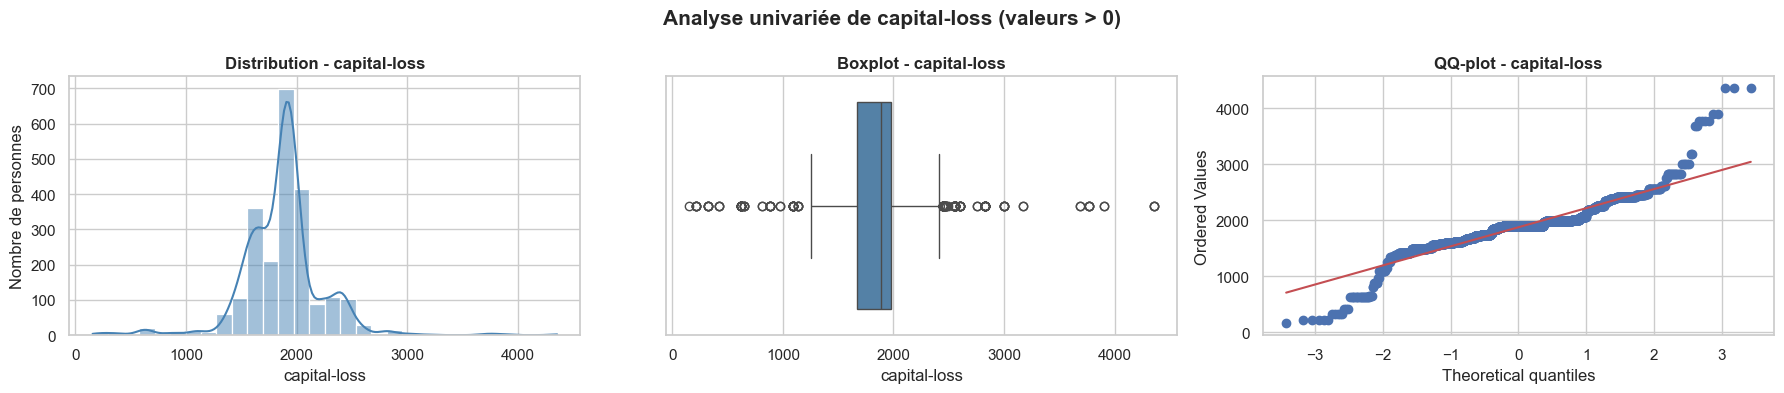

capital-loss (valeurs > 0) : skewness = 0.31 | kurtosis = 7.82


In [13]:
for i in ["capital-gain", "capital-loss"]:
    eda.plot_numerical_univariate(i, filter_positive=True)
    plt.show()

    # Quantification de l'asymétrie et de l'aplatissement (sur les valeurs > 0)
    nonzero = eda.df[i][eda.df[i] > 0]
    print(f"{i} (valeurs > 0) : skewness = {nonzero.skew():.2f} | "
          f"kurtosis = {nonzero.kurt():.2f}")

**Observations**

* **Gain en capital (`capital-gain`)** : on observe que la grande majorité des gens, parmis la minorité de personnes ayant un `capital-gain` > 0, on un gain en capital qui tourne aux alentours des 10000$ (dataset américain, donc on suppose que c'est des $). On observe aussi quelques valeurs aberrantes, notamment le maximum observé tout à l'heure de 99999\$ (surement une valeur plafond de l'enquête). Pas de distribution particulière suivie ici.

* **Perte en capital (`capital-loss`)** : ici, les valeurs sont toujours très concentrées, cette fois autour de 1800/2000$ de perte. Le boxplot est moins biaisé qu'au dessus car il n'y a pas de valeurs aberrantes extrèmes. La distribution n'est pas normale mais est un peu plus équilibrée que celle de `capital-gain`.

Avec la considération des valeurs positives également, la skewness et le kurtosis des deux variables a considérablement diminué, mais `capital-gain` conserve une skewness elevée proportionnellement (rapport x3 environ) en comparaison au kurtosis (rapport x15 environ), ce qui est du à la présence d'outliers extrêmes.

On ne tire pas de conclusions particulières ici sur les données en termes de modélisation, mais il faudra peut-être réfléchir à gérer les valeurs aberrantes dans `capital-gain` (par exemple via normalisation en passant au log, car les moyennes et écarts-type de `capital-gain` sont biaisés, tirés vers le haut par ces quelques valeurs extrêmes). Il pourrait être également possible de faire un encodage binaire pour `capital-loss` car étant donné que la distribution est assez concentrée, elle n'apporte pas beaucoup d'information.

#### 5.1.2 Quantification des outliers (Règle IQR)

In [14]:
eda.outlier_stats()

,n_outliers,pct,lower,upper
feature,,,,
hours-per-week,13496,27.631956,32.50,52.50
capital-gain,4035,8.261332,0.00,0.00
capital-loss,2282,4.672208,0.00,0.00
education-num,1794,3.673068,4.50,16.50
fnlwgt,1453,2.974899,-62586.75,417779.25
age,216,0.442242,-2.00,78.00


On retrouve un taux d'outliers très important pour certaines variables, notamment `hours-per-week`, comme on pouvait le voir dans le boxplot présenté précédemment. Cependant, la règle IQR peut potentiellement biaiser le résultat, en faisant paraitre ces derniers comme des erreurs. Pour rappel, on avait : q1 = 40.0	q2 = 40.0 q3 = 45.0. Le fait que les valeurs soient aussi reserrées donne un écart interquartile très réduit (5). Cela fait que toute personne en dehors de [40-5x1.5 ; 45+5x1.5] = [32,5 ; 52,5] est marquée "outlier", ce qui est assez restrictif.

Pour `age`, il y a écrit -2, ce qui signifie qu'il faudrait avoir -2 ans pour être considéré comme un outlier or c'est impossible donc pas d'outliers possibles par le bas ici.

Il ne faut donc pas les supprimer ou encore les borner, au risque de perdre de l'information. On pourrait s'attarder sur les valeurs type 1h ou 99h, mais elles restent plausibles, d'autant que le bornage à 99h ressemble à un plafond : 

In [15]:
h = X["hours-per-week"]
print(h[h >= 90].value_counts().sort_index())
print(f"\nmax = {h.max()} | nb à 99 = {(h == 99).sum()} | nb à 98 = {(h == 98).sum()}")

hours-per-week
90     42
91      3
92      3
94      1
95      2
96      9
97      2
98     14
99    137
Name: count, dtype: int64

max = 99 | nb à 99 = 137 | nb à 98 = 14


Le pic à 99 confirme bien que c'est une borne max pour l'enquête, mais pas de nécéssité de gérer ça spécifiquement, les valeurs restent plausibles.

### 5.2. Variables catégorielles

On analyse les variables catégorielles en étudiant leurs modalités et leurs effectifs.  
Cela permet d’identifier les catégories dominantes, les catégories rares et les variables ayant beaucoup de modalités.

In [16]:
eda.categorical_stats() # rare : <1% par défaut

,n_unique,top,top_pct,n_rare,missing
feature,,,,,
workclass,8,Private,69.419762,2,2799
education,16,HS-grad,32.316449,2,0
marital-status,7,Married-civ-spouse,45.819172,1,0
occupation,14,Prof-specialty,12.636665,2,2809
relationship,6,Husband,40.366897,0,0
race,5,White,85.504279,2,0
sex,2,Male,66.848204,0,0
native-country,41,United-States,89.742435,39,857


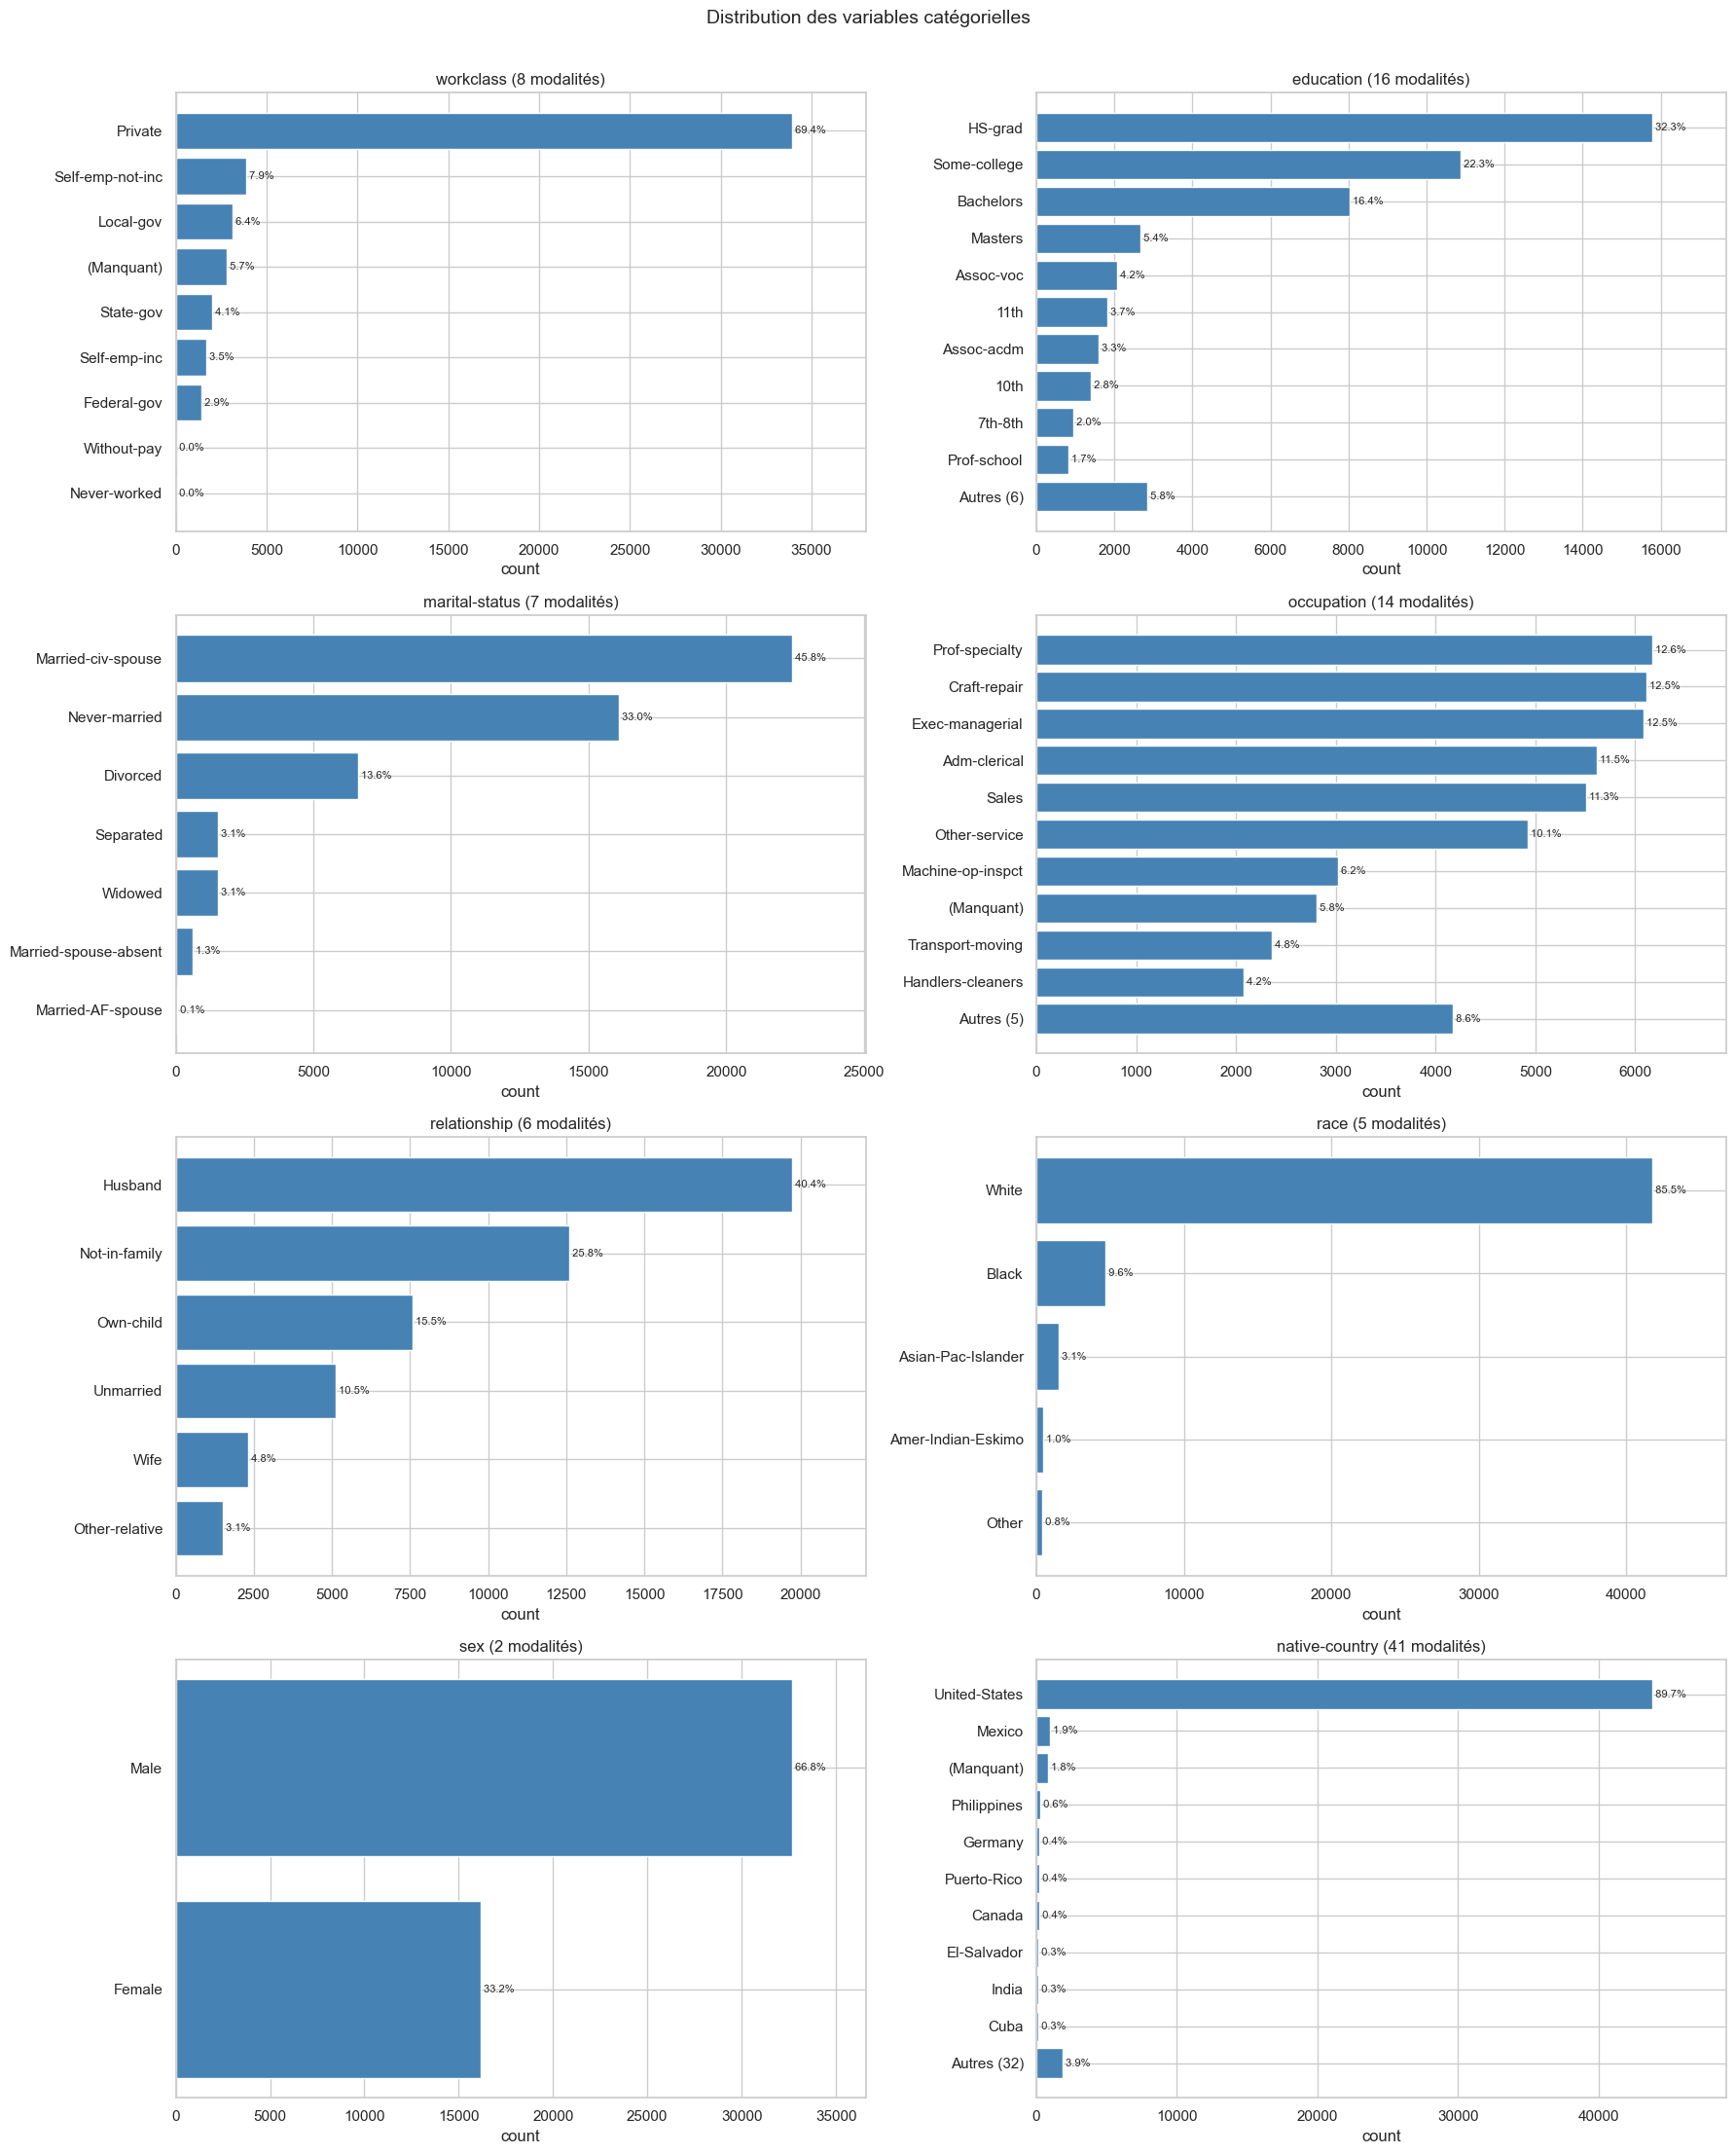

In [17]:
eda.plot_categorical_univariate(); plt.show()

In [18]:
print(eda.df["workclass"].value_counts())

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64


In [19]:
print(eda.df["native-country"].value_counts().head(5))

native-country
United-States    43832
Mexico             951
Philippines        295
Germany            206
Puerto-Rico        184
Name: count, dtype: int64


**Observations**

L’analyse des variables catégorielles met en évidence des catégories dominantes, des catégories rares et certaines variables possédant un nombre important de modalités.

* **`workclass`** : la catégorie `Private` est très largement majoritaire. Les catégories `Without-pay` et `Never-worked` sont très rares. La variable est assez fortement déséquilibrée.

* **`education`** : les modalités les plus fréquentes sont `HS-grad`, `Some-college` et `Bachelors`. Les autres niveaux d’éducation sont moins représentés. Cette variable possède un nombre assez important de modalités, mais reste relativement équilibrée.

* **`marital_status`** : les catégories `Married-civ-spouse` et `Never-married` sont dominantes, suivies par `Divorced`. Les situations comme `Married-spouse-absent` sont rares.

* **`occupation`** : plusieurs professions sont bien représentées, notamment `Prof-specialty`, `Craft-repair`, `Exec-managerial` et `Adm-clerical`. La répartition est plus équilibrée que pour les autres variables, même si certaines professions sont peu fréquentes. Cette variable contient un nombre assez important de modalités.

* **`relationship`** : les catégories `Husband`, `Not-in-family` et `Own-child` sont les plus représentées. Les modalités `Wife` et `Other-relative` sont plus rares.

* **`race`** : la catégorie `White` est très largement majoritaire. Les autres catégories, en particulier `Amer-Indian-Eskimo` et `Other`, sont peu représentées. Cette variable est donc fortement déséquilibrée.

* **`sex`** : les hommes sont nettement plus nombreux que les femmes dans le jeu de données. (point interessant à noter)

* **`native_country`** : la grande majorité des individus vient des `United-States`. Les autres pays sont très peu représentés. Cette variable possède beaucoup de modalités, mais la plupart sont rares. Cette variable est la plus déséquilibrée du dataset (catégorielle). Il pourrait potentiellement être intéréssant de créer une modalité `Other` représentant les pays particulièrement sous représentés (par exemple < 100 individus) afin de réduire le nombre de modalités, en sachant que 39 modalités sur 41 ne sont présentes que <1% du temps.

Globalement, plusieurs variables catégorielles sont déséquilibrées, dont certaines présentent un fort déséquilibre (notamment `race`, `workclass` ou encore `native_country`). Les variables `education`, `occupation` et surtout `native_country` possèdent un nombre important de modalités (> 14).

Lors du prétraitement, les valeurs manquantes pourront par exemple être remplacées par la modalité la plus fréquente, en tout cas pour `native_country` et `workclass`. Pour `occupation` en revanche, il pourrait convenir de créer une modalité "unknown" car les modalités les plus fréquentes se talonnent de près, et donner 5.8% de valeurs en plus à une de ces modalités peut être néfaste pour la modélisation.

Nous pensons que les variables catégorielles dont le nombre de modalités dépasse 15 (`education` et `native_country`) pourraient être encodées d'une autre manière qu'un one-hot, car cela augmenterait trop la dimensionnalité. Nous pensons par exemple à du TargetEncoding ou encore du LabelEncoding. Les autres variables seront certaintement encodées à l'aide du one-hot encoding. (pour éducation, on verra par la suite qu'en fait c'est la meme chose qu'education num donc l'encodage ordinal est bien)

## 6. Analyse bivariée

### 6.1 Variables numériques et cible

In [20]:
eda.numerical_stats(by_class=True).style.format("{:,.1f}")

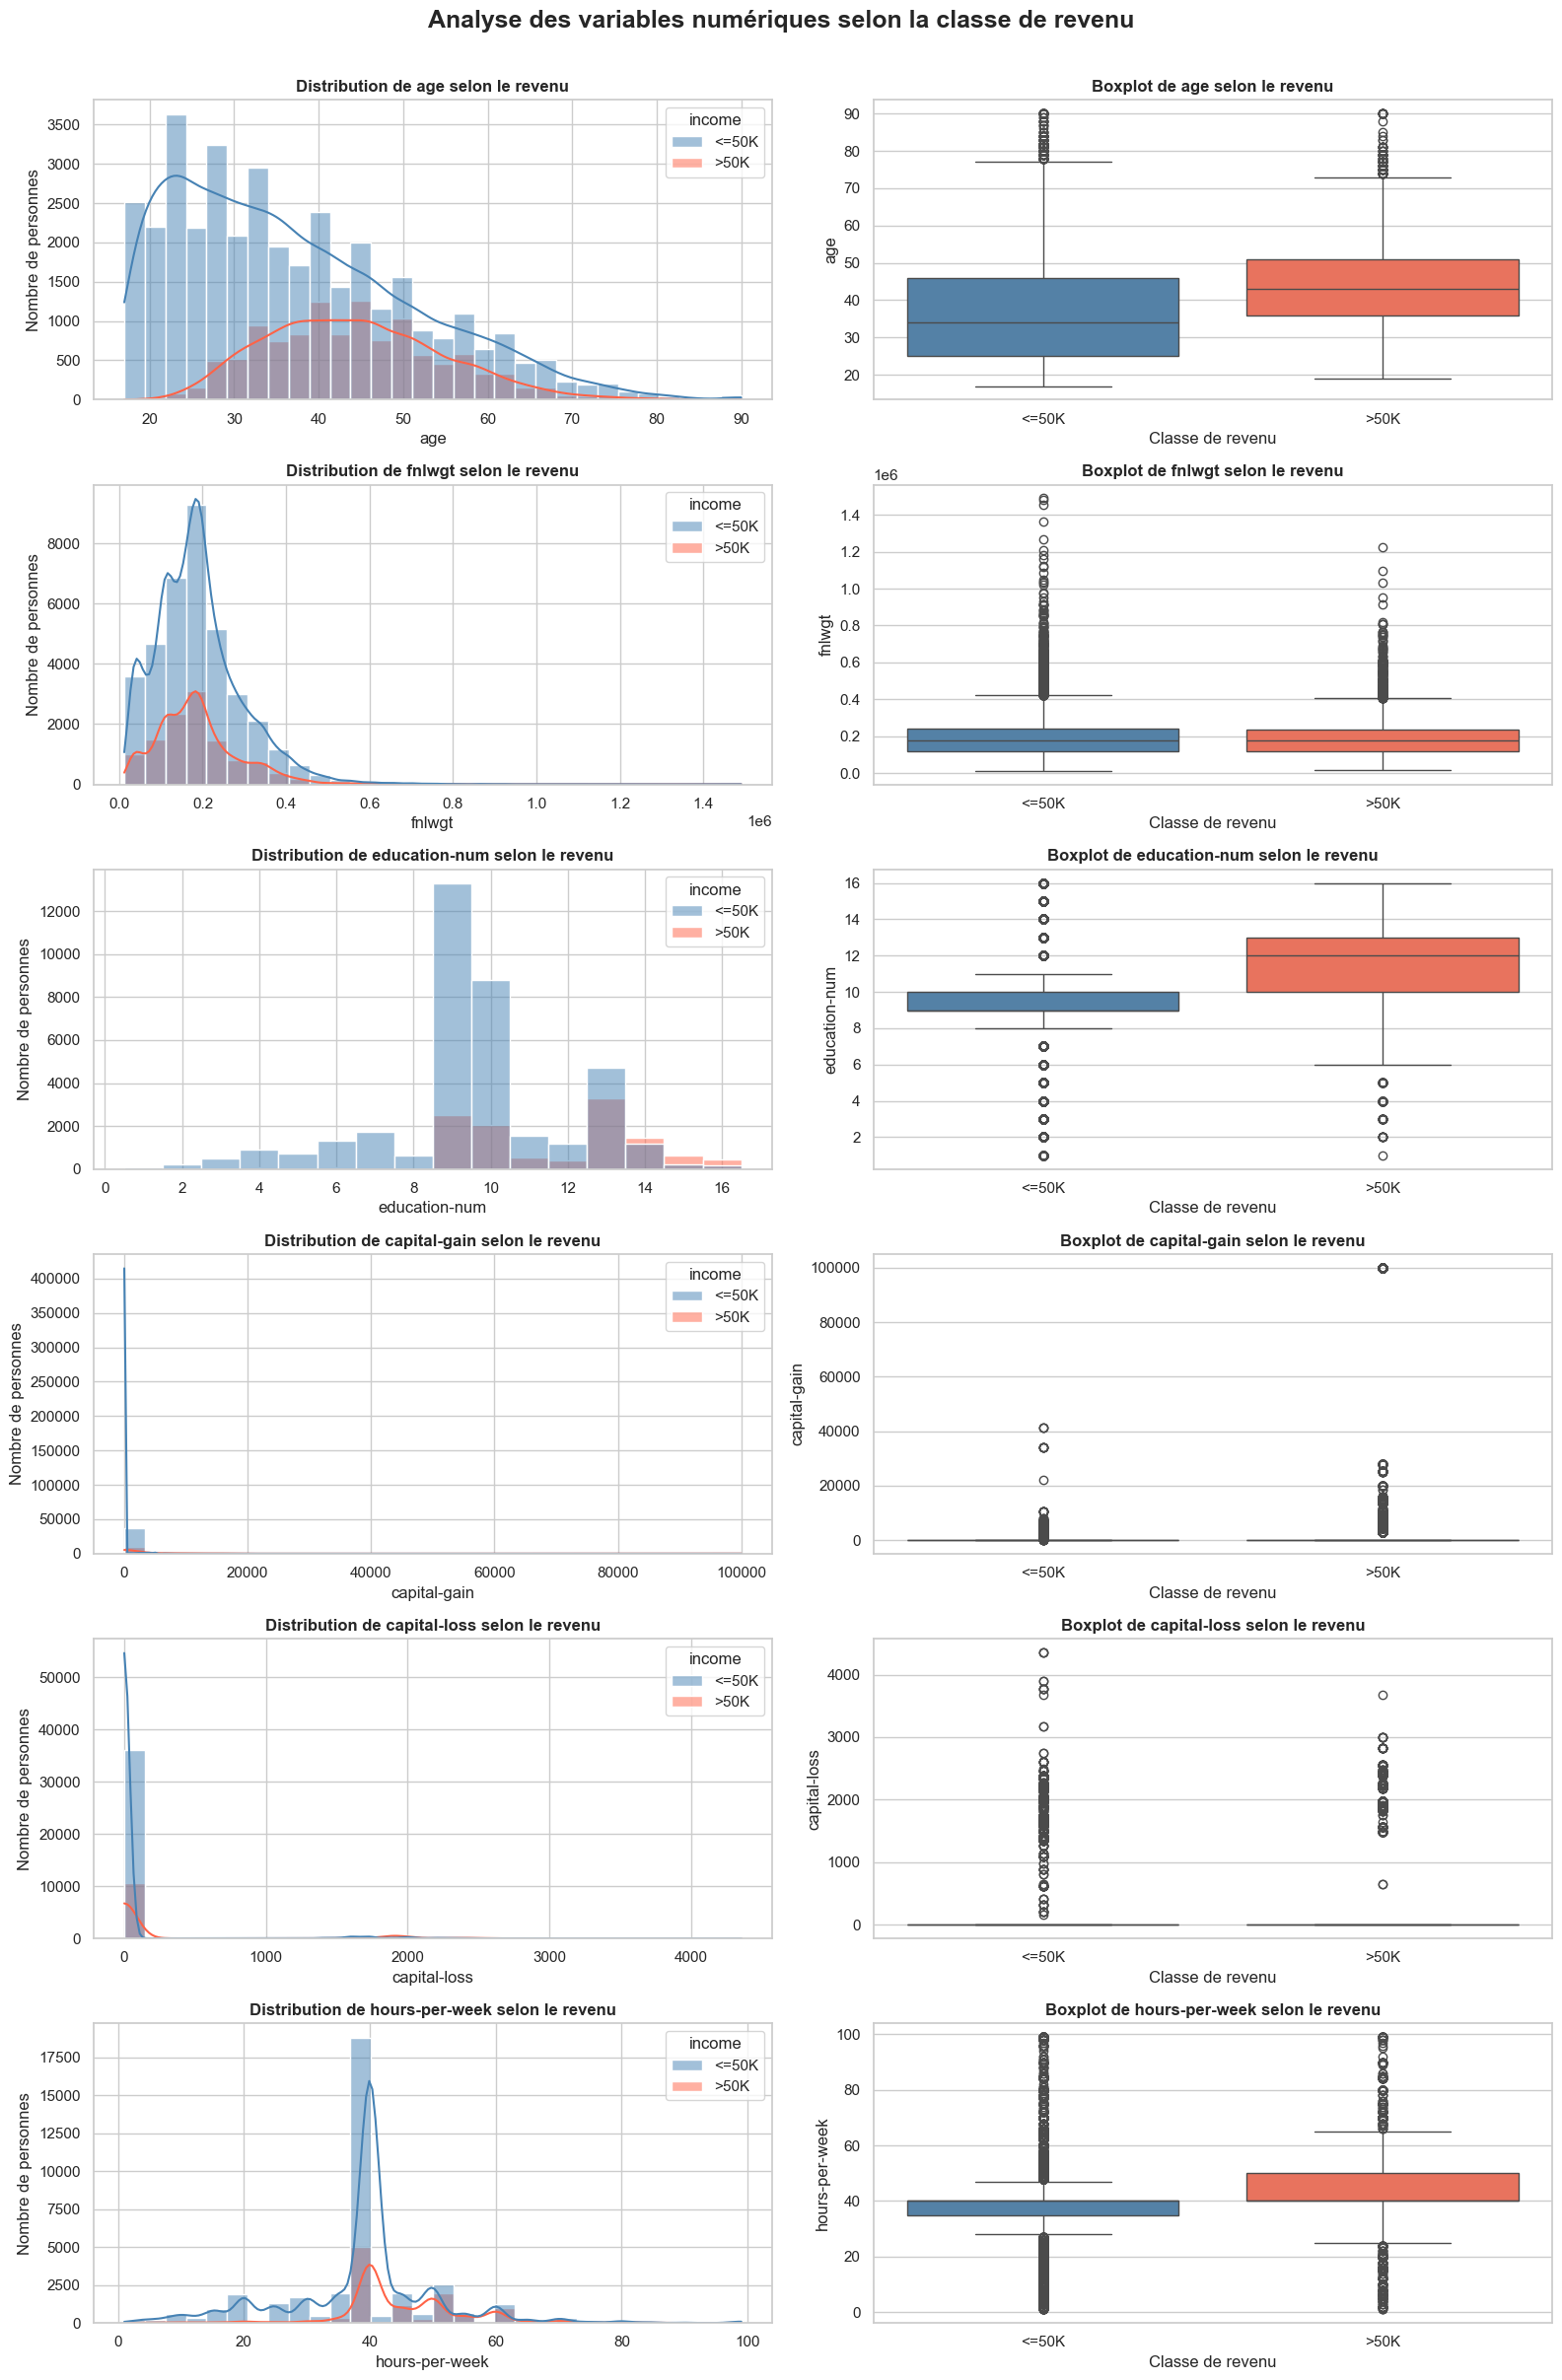

In [21]:
eda.plot_numerical_bivariate()
plt.show()

**Observations**

L’analyse des variables numériques montre que certaines variables semblent différencier les deux classes de revenu.

`Âge` : Les individus ayant un revenu supérieur à 50K sont généralement plus âgés que ceux ayant un revenu inférieur ou égal à 50K (âge médian des personnes >50k de 9 ans supérieur à celui des personnes <=50k, âge moyen presque la même chose). 

`fnlwgt` : La variable fnlwgt présente une forte dispersion, mais elle ne semble pas clairement séparer les deux classes de revenu. Comme énoncé précemment, cette variable est déjà problématique de par son aspect arbitraire et assez obscur, mais on voit en plus ici que la distribution est très similaire pour les deux classes.

`education-num` : On observe aussi qu’ils ont souvent un nombre d’années d’éducation plus élevé (en moyenne 2 ans d'éducation de plus pour les personnes à revenu >50k).

`capital-gain` : Les distributions et boxplot sont écrasés par les valeurs aberrantes, ce problème n'a pas changé malgré la séparation par classe de la variable cible. On voit en revanche que la valeur moyenne en fonction des groupes est très différente (147.0 (<=50k) VS 4,042.2 (>50k)), ce qui est du à la présence de la valeur extrême 99999. Nous regarderons en profondeur cette variable ci-dessous.

`capital-loss` : Même raisonnement que pour capital-gain, cette variable sera étudiée plus tard. On observe en revanche que le nombre de personnes ayant une perte de capital positive a l'air proportionnellement supérieur chez les individus ayant un revenu <=50k.

`hours_per_week` : Les personnes gagnant plus de 50K travaillent davantage d’heures par semaine en moyenne (38.8h VS 45.5h). En revanche, la médiane est la même car une très forte majorité de personnes travaillent 40h, peu importe le groupe de personnes (<=50k ou >50k)


Globalement, on observe que les variables `Âge`, `education-num` et `hours_per_week` diffèrent vraiment en fonction de la classe, donc apportent un vrai pouvoir décisionnel pour le modèle. **VALIDER AVEC TESTS HYPOTHESE ? OU TROP COMPLIQUE AVEC LE NOMBRE DE DATA**Cela parait logique que les personnes plus agés, plus diplomés et qui travailent plus aient de meilleurs revenus.
Concernant `capital-gain` et `capital-loss`, nous allons rentrer un peu plus dans le détail pour voir si parmis les valeurs non égales à 0, il y a des différences de distribution en fonction des classes.
Enfin, pour `fnlwgt`, il semble y avoir assez peu d'intérêt à garder cette variable, mais nous effectuerons des tests d'hypothèses pour vérifier si la supprimer est correct ou non

#### 6.1.1. Analyse bivariées des variales capital-gain et capital-loss sans les valeurs nulles

In [22]:
print(eda.zero_proportion_by_class(["capital-gain", "capital-loss"]))

                           = 0        > 0
variable     income                      
capital-gain <=50K   95.844435   4.155565
             >50K    78.685719  21.314281
capital-loss <=50K   96.937155   3.062845
             >50K    90.211346   9.788654


In [23]:
print(eda.zero_proportion_by_class(["capital-gain", "capital-loss"], normalize=False))

                       = 0   > 0
variable     income             
capital-gain <=50K   35611  1544
             >50K     9196  2491
capital-loss <=50K   36017  1138
             >50K    10543  1144


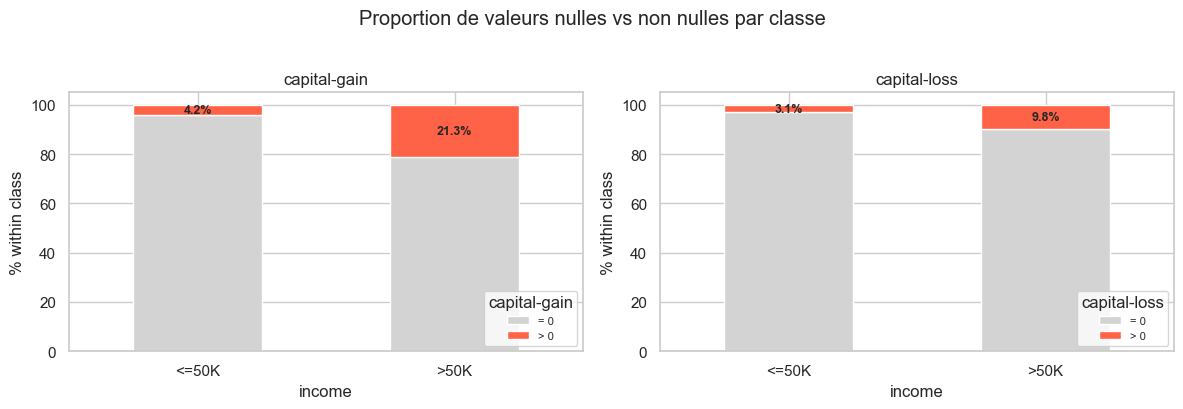

In [24]:
eda.plot_zero_proportion_by_class(["capital-gain", "capital-loss"]);

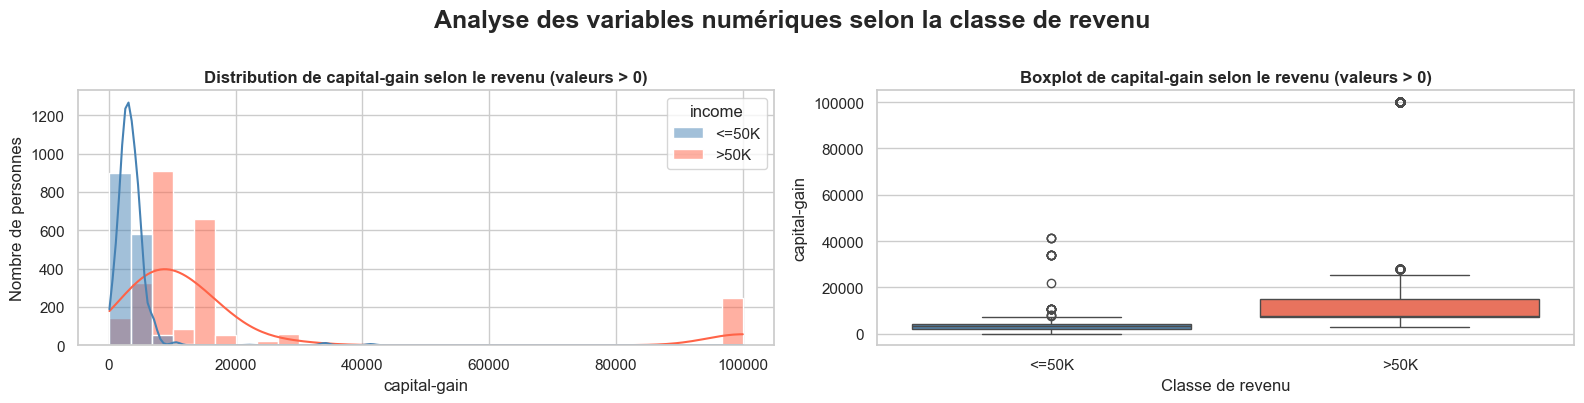

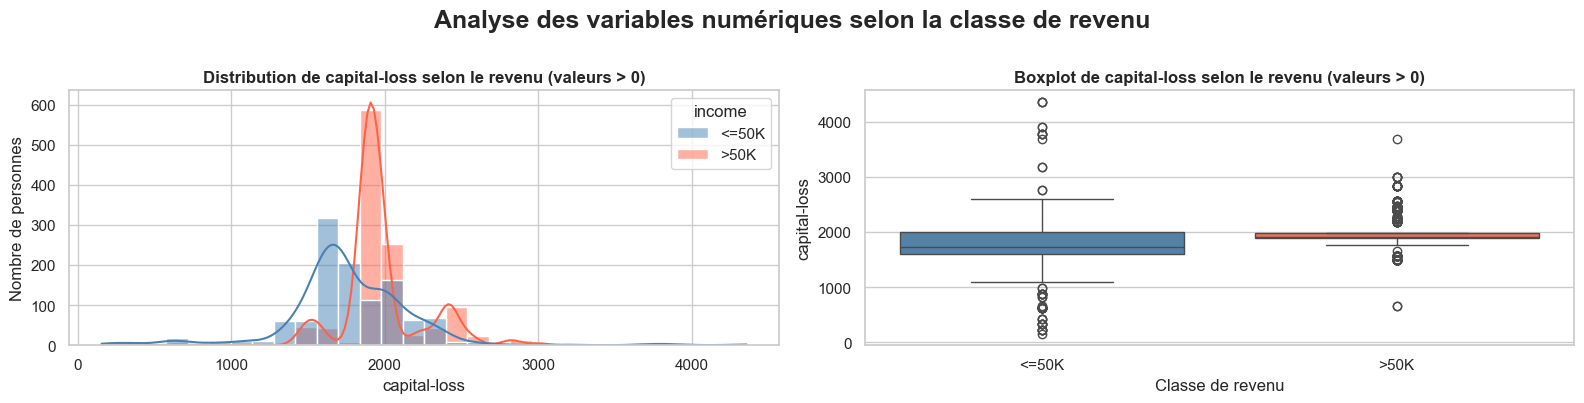

In [25]:
for i in ["capital-gain", "capital-loss"]:
    eda.plot_numerical_bivariate(i, filter_positive=True)
    plt.show()

**Observations**

* **Gain en capital (`capital-gain`)** : Le premier point important et que l'on remarque directement est que la proportion des individus ayant eu un gain en capital est bien plus élevé chez les ceux qui ont un revenu >50k (21,3% contre 4,2%). Cette simple observation nous permet de dire que la variable est intéressante à conserver car elle apporte une information sur la classe. Le passage au log mentionné précédemment pourrait fortement aider à régler le problème de la présence de valeurs aberrantes. Pour aider certains modèles (tels que SVM) à définir le seuil, il pourrait être possible de rajouter une variable binaire "has_capital_gain". Les modèles à base d'arbres de décision en bénéficieront en revanche moins.

* **Perte en capital (`capital-loss`)** : On observe que les personnes ayant un revenu >50k ont aussi 3x plus perdu de capital dans l'année que les personnes ayant un revenu <=50k. Elle reste en revanche très concentrée pour les deux classes (avec quelques outliers mais qui restent assez légers en comparaison des outliers trouvés dans `capital-gain`) et surtout pour la classe >50k, qui est concentrée autour de 2000. Comme mentionné précédemment, un passage à une variable binaire pourrait "has_capital_loss" pourrait s'avérer intéressante.


Concernant l'interprétation globale et en particulier pour `capital-loss`, ce n'est pas forcément étonnant : ces variables représentent du gain/perte de capital au sein d'une année. Les personnes aux revenus élevés (>50k) sont plus à même d'investir de l'argent en bourse ou dans l'immobilier par exemple. Avoir du `capital-gain` non nul est déjà un fort signal de richesse. On voit aussi que les montants élevés sont en grande partie associés à la classe >50k, ce qui montre que ces personnes ont effectué des plus gros investissements. Enfin, pour `capital-loss`, comme tout investissement comporte des risques, il est également cohérent que les personnes qui ont plus d'argent à investir, soient aussi plus à même d'en perdre.

#### 6.1.2 Analyse de la corrélation variables numériques / variable cible

In [26]:
eda.numeric_target_correlation()

education-num     0.332613
age               0.230369
hours-per-week    0.227687
capital-gain      0.223013
capital-loss      0.147554
fnlwgt           -0.006339
dtype: float64

La corrélation avec la cible permet d’avoir une première indication sur les variables numériques les plus associées au revenu.  
La variable `education_num` est généralement positivement corrélée avec la classe `>50K`, ce qui confirme l’importance du niveau d’éducation, et nos suppositions passées.  
Cependant, ces corrélations ne capturent que des relations linéaires et ne suffisent pas à conclure sur la performance prédictive des modèles.

On voit également que, linairement, `fnlwgt` semble avec un intéret assez réduit pour la prédiction (linéairement en tout cas).

**POTENTIELLEMENT ALLER PLUS LOIN QUE CA ?**

### 6.2 Variables catégorielles et cible

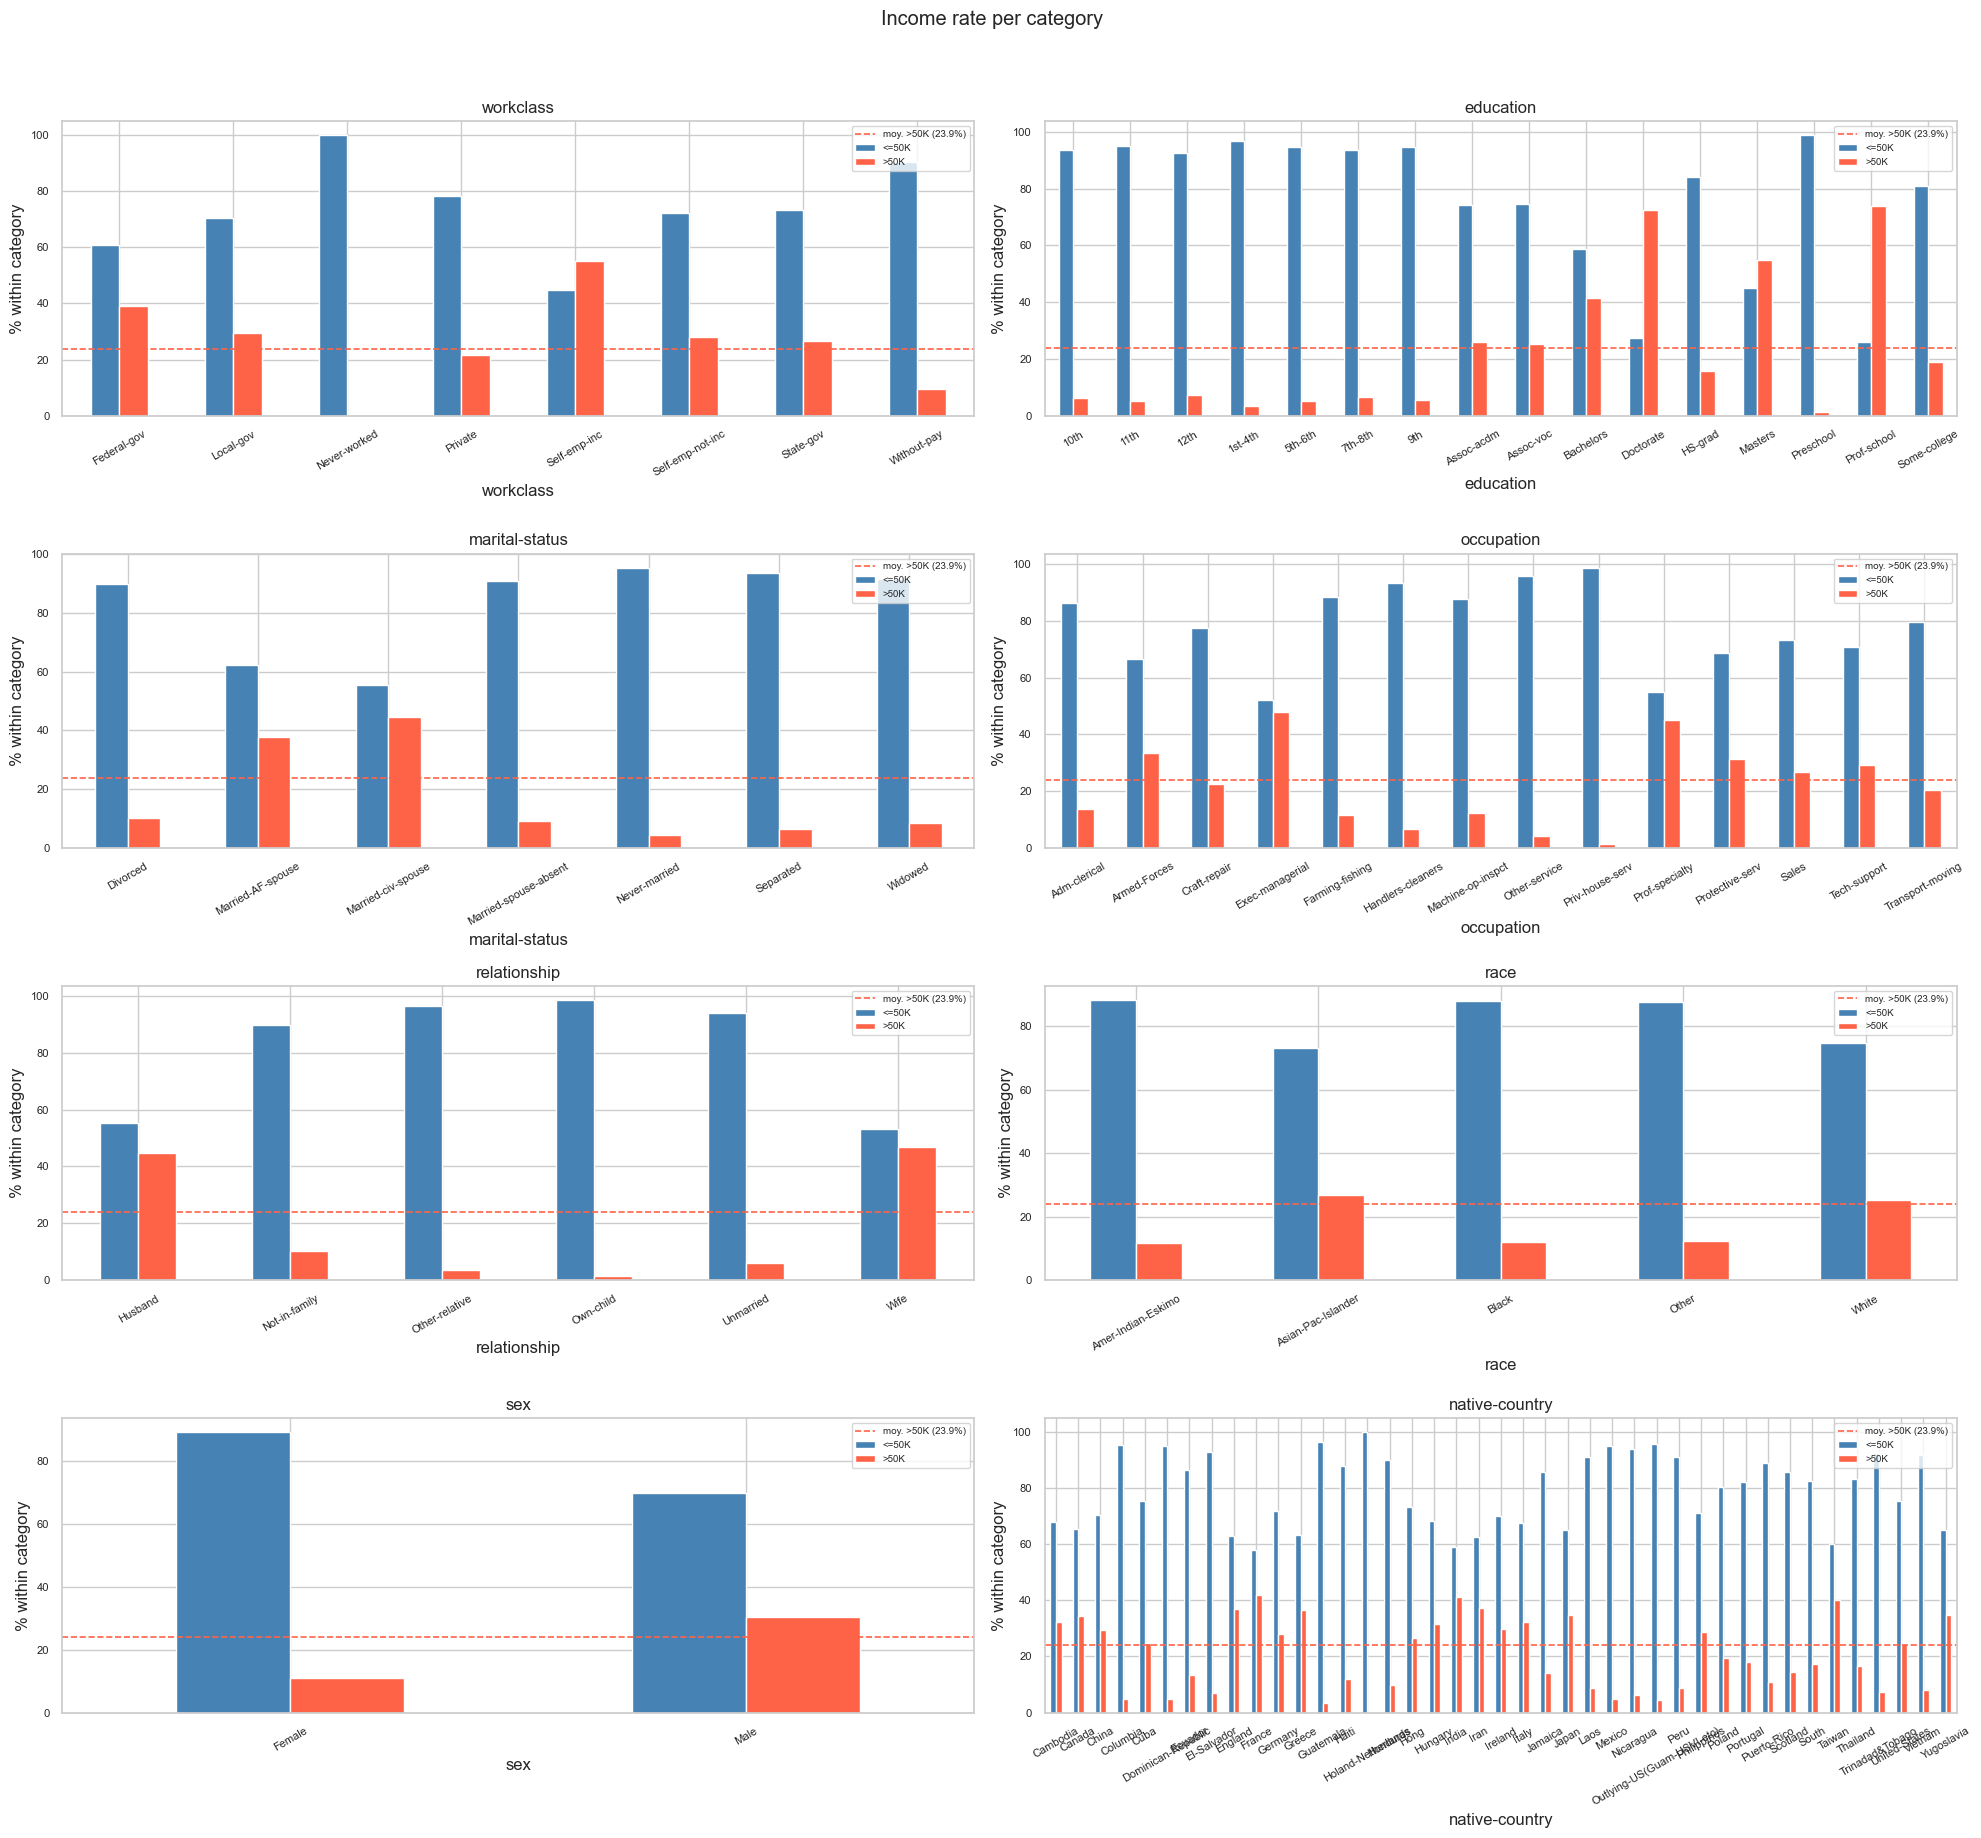

In [27]:
eda.plot_categorical_bivariate()
plt.show()

Dans ces graphiques, plus les barres varient d'une modalité à l'autre (et plus ces variations sont importantes par rapport à la moyenne), plus la variable est significative.

Pour rappel, la proportion moyenne d'individus (<=50k / >50k) calculée précédemment est telle que : (76.1%/23.9%).

La proportion moyenne de personnes ayant >50k de revenus est donc de 23.9%, ce qui signifie que si on s'écarte fortement de ce nombre, notre modalité est significative pour la décision. 

On représente par ailleurs cette proportion moyenne avec la ligne pointillée orange visible sur le graph.

Certaines variables semblent plus discriminatrices que d'autres, par exemple : 
- `relationship` avec les modalités Wife et Husband, qui montre un lien assez fort avec le fait d'avoir un revenu >50k, ou à l'inverse Own-Child, qui montre un lien assez fort avec, à l'inverse, le fait d'avoir un revenu <=50k.
- `occupation` dans laquelle on voit des modalités telles que Exec-managerial ou prof-specialty apparaitre être significative de revenu >50k, ce qui parait cohérent d'un point de vue logique. À l'inverse on retrouve private house service qui signifie l'inverse, ce qui là aussi parait cohérent avec la réalité (cols blancs vs cols bleus).
- `education` est elle aussi très significative, notamment avec des gros pics sur les modalités doctorate, prof-schools et masters
- ...

Globalement, toutes les variables ici présentes semblent avoir un intérêt pour la modélisation, certains tout particulièrement (`education` notamment) et d'autres un peu moins (`race`, `native-country`). Pour ces dernieres, et notamment `native-country` qui est très déséquilibrée (USA sur-représentés). Ce déséquilibre fait que on pourrait croire que les autres pays ont une importance, mais ça peut être du au bruit d'échantillonnage, car comme on l'a vu précédemment, 39 modalités sur 41 ne représentent que <1% du total des échantillons.

On veut donc garder toutes ces variables catégorielles et les encoder correctement afin d'en extraire le plus d'information. Il peut cependant être intéressant d'étudier plus en profondeur `native-country` ainsi que les autres variables pour savoir si le bruit peut-être à la source de ces variations.

#### 6.2.1 Analyse des taux de hauts revenus

Cette partie permet de vérifier que les variations des barres dans le graphique précédent sont dues ou ne sont pas dues à du bruit d'échantillonnage

In [28]:
with pd.option_context("display.max_rows", None):
    print(eda.income_rate_by(["education", "occupation", "marital-status", 
                              "relationship", "native-country", "race", "workclass", "sex"], dropna=False).round(1))

                                           effectif  taux_>50K (%)
variable       modalité                                           
education      Prof-school                      834           74.0
               Doctorate                        594           72.6
               Masters                         2657           54.9
               Bachelors                       8025           41.3
               Assoc-acdm                      1601           25.8
               Assoc-voc                       2061           25.3
               Some-college                   10878           19.0
               HS-grad                        15784           15.9
               12th                             657            7.3
               7th-8th                          955            6.5
               10th                            1389            6.3
               9th                              756            5.4
               5th-6th                          509           

In [29]:
rare_rows = []

for col in CATEGORICAL_FEATURES:
    counts = X[col].value_counts(dropna=False)
    rare_count = (counts < 50).sum()
    rare_rows.append({
        "Variable": col,
        "Nombre de modalités": counts.shape[0],
        "Modalités avec moins de 50 observations": rare_count,
        "Modalité la plus fréquente": counts.index[0],
    })

rare_table = pd.DataFrame(rare_rows).sort_values("Modalités avec moins de 50 observations", ascending=False)
rare_table

,Variable,Nombre de modalités,Modalités avec moins de 50 observations,Modalité la plus fréquente
7,native-country,42,17,United-States
0,workclass,9,2,Private
3,occupation,15,1,Prof-specialty
2,marital-status,7,1,Married-civ-spouse
1,education,16,0,HS-grad
4,relationship,6,0,Husband
5,race,5,0,White
6,sex,2,0,Male


`Observations` :

- `education` : Pas d'alerte sur cette variable, il n'y a pas de modalités avec un effectif très bas (hormis peut-être Preschool) et on voit bien l'évolution du taux de >50k plus le diplôme devient difficile/prestigieux

- `occupation` : Ici en revanche, Armed-Forces a probablement un taux elevé de >50k du fait de son très faible échantillonnage (15). Toutefois, les autres variables étant toutes bien échantillonnées et les variations étant importantes en fonction des modalités, il ne semble pas nécéssaire d'appliquer un traitement particulier à cette variable. La création d'un modalité `Unknown` énoncée précédemment semble être pertinente ici, car en plus de ce qui a été expliqué plus haut, le taux de >50k s'éloigne de manière assez importante des top modalités de cette variable (celles par lesquelles on aurait pu imputer).

- `marital-status` : Même raisonnement qu'au dessus, une modalité (Married-AF-spouse, où AF veut par ailleurs dire Armed Forces) a un fort taux de >50k, qui peut être du au hasard du fait de son faible échantillonnage (37). Le reste des variables étant bien échantillionnées et semblant significatives, pas de traitement particulier à première vue.

- `relationship` : Pas d'alerte ici, les modalités semblent toutes +- significatives

- `native-country`: Pour cette variable en revanche, on a beaucoup de variables avec un faible échantillonnage (17), donc pour ces dernières, le taux elevé (notamment celui de france : 42.1 ou de yougoslavie : 34.8) est probablement du au hasard. Cette observation renforce notre idée quant au fait de regrouper les variables à faible effectif dans une modalité `Others`. Une autre observation interessante est que le taux de >50k de `Missing` semble plus ou moins équivalent à celui de `United States`. Notre proposition de remplacer les manquants par la modalité la plus fréquente (`United States`) semble alors cohérente.

- `workclass`: Pour cette variable, on a 2 modalités rares pour lesquelles il est probable que le hasard aie défini leur taux de >50k. Créer une modalité `Others` serait possible mais pas indispensable non plus. En revanche, on observe que le taux de >50k des `Missing` est bien moins élevé que celui des `Private` (9.5 VS 21.8). Il pourrait de ce fait être intéressant là aussi de créer une feature `Unknown` plutot que de remplacer avec la modalité la plus fréquente.

- RAS pour `race` et `sex`

Suite à ces observations, on voit également un rapprochement (peut-être du au hasard ou à une coincidence) entre l'effectif et le taux de >50k des `Missing` de `occupation` et de ceux de `workclass`

#### 6.2.2. Analyse de l'association variables catégorielles / variable cible

In [30]:
eda.cramers_v_matrix(include_target=True)["income"].drop("income").sort_values(ascending=False)

relationship      0.454379
marital-status    0.448170
education         0.365452
occupation        0.345321
sex               0.214532
workclass         0.163579
race              0.099447
native-country    0.092569
Name: income, dtype: float64

Cette notion n'a pas été directemnt abordée en cours, mais elle nous permet de montrer mathématiquement nos observations.

Elle représente une force de dépendance comprise entre 0 et 1, et plus cette force s'approche de 1 pour une variable donnée, plus cela signifie que la cible dépend de la variable en question. On parle ici d'association et pas de corrélation car la corrélation concerne plutôt les variables numériques (bien que la corrélation avec le coefficient de pearson puisse être utilisée avec une cible binaire et des variables numériques). Elle se base sur le test d'indépendance du chi2.

Cette mesure peut s'interpréter de la manière suivante : 

![illustration_cramerV_interpretation](../img/cramerExcel.png)

Le degré de liberté df de Cramer's V se déduit de la manière suivante 
$$df = min(nb\_modalités\_variable, nb\_modalités\_cible) - 1$$
Or dans notre cas, on a une cible binaire, donc dont le nombre de modalités vaut toujours 2. Ce qui signifie qu'on a toujours $df = 1$.


On voit donc que `relationship` et `marital-status` arrivent en tête avec une dépendance moyenne-forte devant `education` ou `occupation` qui ont une dépendance moyenne à la variable cible.

Pour comparer avec les graphiques présentés avant, où visuellement, `education` par exemple semblait se démarquer d'avantage, on peut attribuer ça au fait qu'on a beaucoup de monde dans des modalités à fort écart par rapport à la moyenne (Married-civ-spouse et Never-married) chez `relationship` (valable aussi chez et `marital-status`), alors que le "peuplement" des modalités d'`education` est plus progressif, avec au final relativement peu de valeurs dans les modalités extrêmes (malgré le fait qu'elles soient encore plus extrêmes). (deux pics VS étalé et pas mal de monde au centre quand même)

SInon, on voit que la cible `income` semble être assez peu dépendante de `race` et `native-country`, comme ce que nous faisaient présager les observations (et inversement car Cramer's V est symétrique).

## 7. Analyse approfondie

### 7.1. Analyse relations variables quantitatives / quantitatives

peut etre faire un rename pour quanti/quali au lieu de caté/numérique (les deux sont valables mais l'un est proba et l'autre datascience/ml)

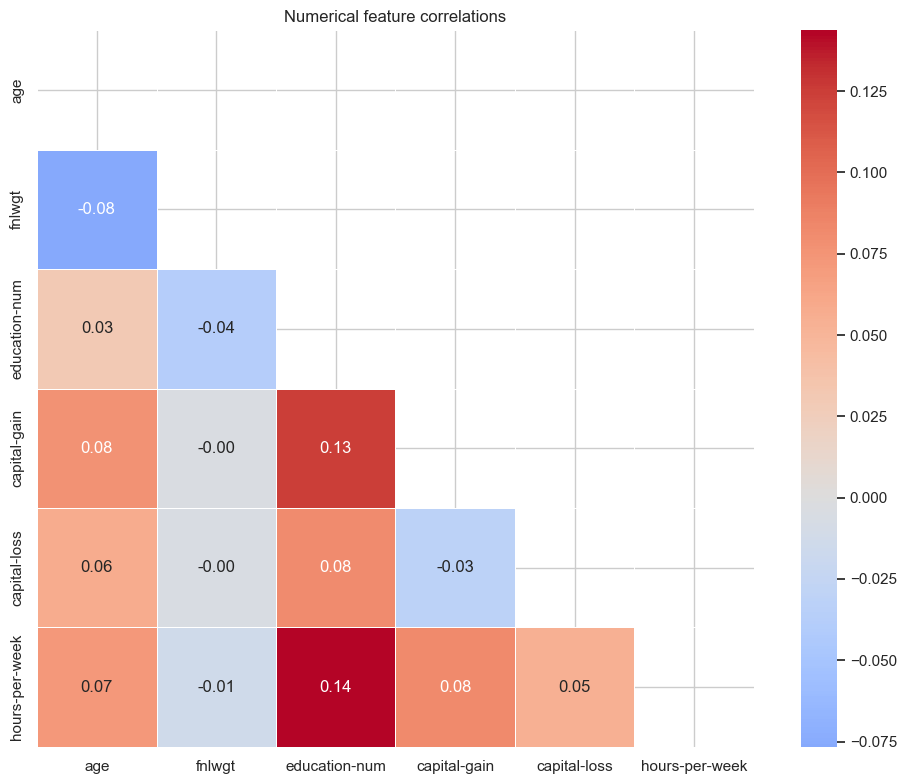

In [31]:
eda.plot_correlation_matrix()
plt.show()

**Observations** :

La matrice de corrélation montre que les variables numériques sont globalement peu corrélées entre elles, en tout cas linéairement.  
La plupart des coefficients sont proches de 0, ce qui indique l’absence de relation linéaire forte entre ces variables.

Les corrélations les plus visibles restent faibles, on a par exemple :
- `education_num` et `hours_per_week` : corrélation d’environ 0.14
- `education_num` et `capital_gain` : corrélation d’environ 0.13
- `age` et `capital_gain` : corrélation d’environ 0.08
- `age` et `hours_per_week` : corrélation d’environ 0.07

On observe aussi une légère corrélation négative entre `age` et `fnlwgt`, autour de -0.08, mais elle reste très faible.

Globalement, cette matrice ne met pas en évidence de forte multicolinéarité entre les variables numériques. Cela signifie que les variables numériques apportent des informations relativement distinctes au modèle. Selon cette matrice, on a pas de variables à supprimer en particulier.

### 7.1. Analyse relations variables qualitatives / qualitatives

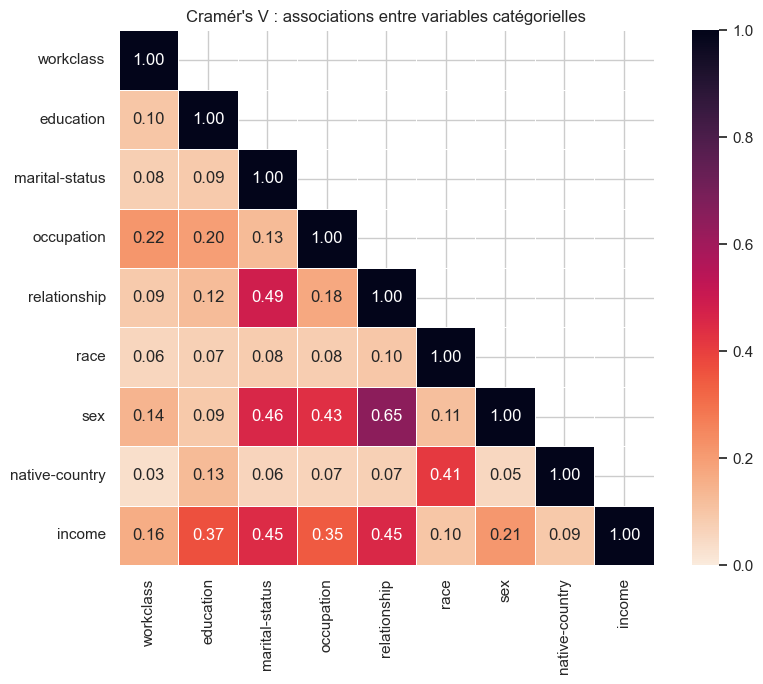

In [32]:
eda.plot_cramers_v_matrix(include_target=True)
plt.show()

On utilise ici Cramer'V pour regarder l'association entre les différentes variables catégorielles du dataset.
Bien que cette matrice soient difficile à interpréter lorsque les variables ont beaucoup de modalités (voir explication précédemment), on peut toujours repérer des liens plus forts chez certaines variables que chez d'autres.

`sex` : l'interprétation se fait selon df=1 dans le tableau présenté précédemment car sex est une variable binaire. On voit que l'association entre `sex` et `relationship` est forte voir très forte, ce qui est logique quand on sait que husband signifie être un homme et wife signifie être une femme, et que ces deux modalités représentent une part importante des effectifs totaux du dataset. On a également des liens moyens/forts avec `occupation` et `marital-status`.

`native-country` : bien que l'interpretation soit plus difficile ici du fait du nombre de modalités des deux variables, on voit que `race` a un lien plus fort que les autres avec cette denrière, ce qui est cohérent.

`marital-status` : on voit un lien assez important avec `relationship` (toujours difficile à interpréter bien plus élevé que le autres)

On peut constater que certaines variables semblent fortement associées, pour ces dernières, nous allons, dans la partie, voir s'il est utile de les garder car elles apportent tout de même de l'information ou si elles sont trop corrélées à d'autres, auquel cas ou pourrait les supprimer pour réduire la complexité.

### 7.2. Analyses bivariées ciblées

#### 7.2.1. `education` et `education-num`

In [33]:
# education-num est-il une simple recodification de education ?
mapping = X.groupby("education")["education-num"].nunique()
print(f"Chaque modalité d'education = une seule valeur d'education-num ? {(mapping == 1).all()}")
X.groupby("education")["education-num"].first().sort_values()

Chaque modalité d'education = une seule valeur d'education-num ? True


education
Preschool        1
1st-4th          2
5th-6th          3
7th-8th          4
9th              5
10th             6
11th             7
12th             8
HS-grad          9
Some-college    10
Assoc-voc       11
Assoc-acdm      12
Bachelors       13
Masters         14
Prof-school     15
Doctorate       16
Name: education-num, dtype: int64

rc (par education)    : [ 1.2   3.24  5.3   6.49  5.42  6.26  5.08  7.31 15.86 18.96 25.33 25.8
 41.28 54.91 73.98 72.56]
rn (par education-num): [ 1.2   3.24  5.3   6.49  5.42  6.26  5.08  7.31 15.86 18.96 25.33 25.8
 41.28 54.91 73.98 72.56]
Taux identiques entre les deux groupements ? True


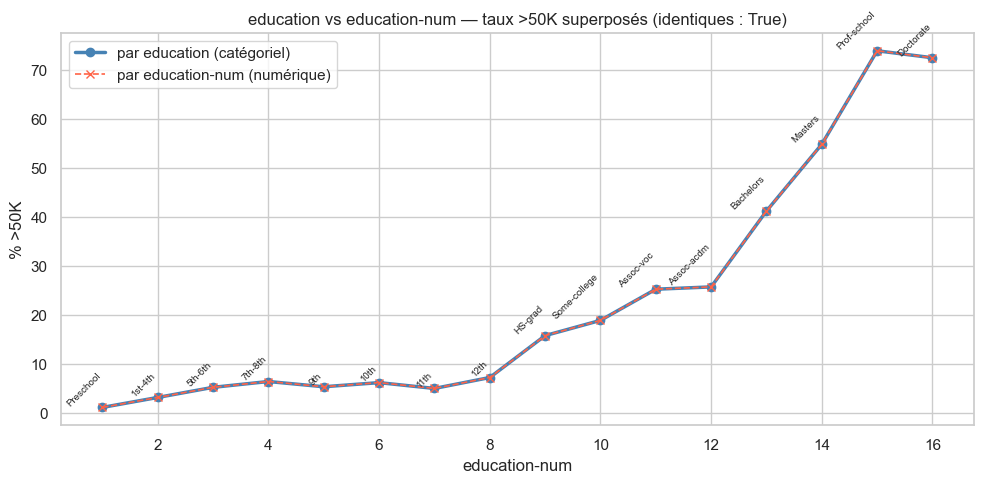

In [34]:
eda.plot_education_equivalence(verbose=True);

Sur ce graphique, on observe clairement que `education` et `education-num` se superposent parfaitement, et que les taux d'individus à >50k d'`income` sont les mêmes. 

On voit également bien l'augmentation progressive de ce taux au fur et à mesure que l'éducation augmente. Cela signifie qu'on a bien une variable qualitative ordinale (`education-num`), et que son encodage tel quel est correct pour la modélisation.

On supprimera par conséquent lors du prétraitement la variable `education`, redondante, afin de réduire la complexite du problème.

#### 7.2.1. `marital-status` et `relationship`

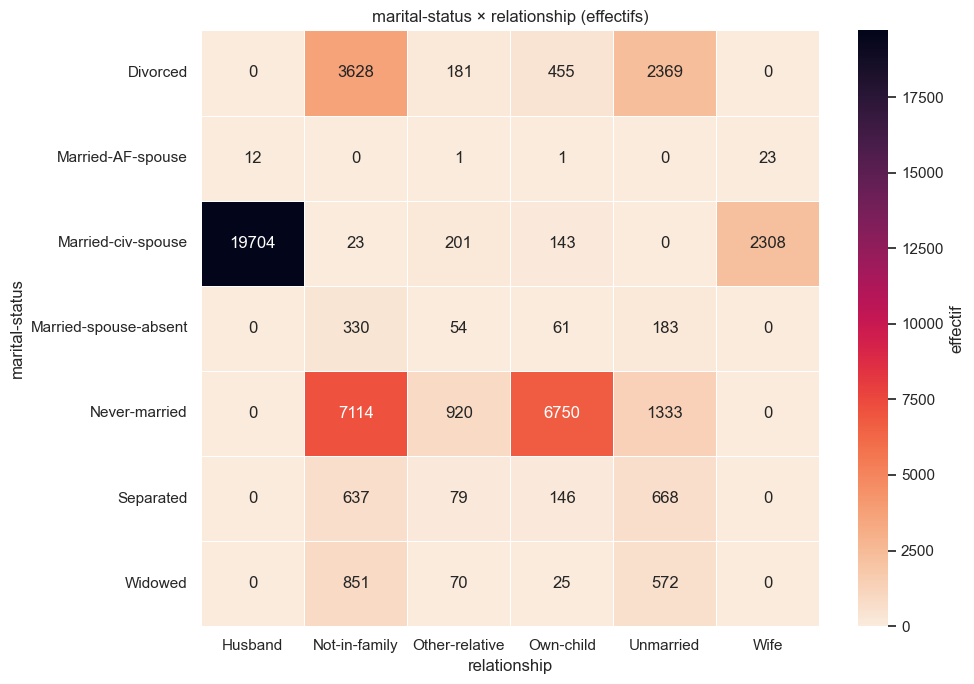

In [35]:
eda.plot_categorical_crosstab("marital-status", "relationship", normalize=None);

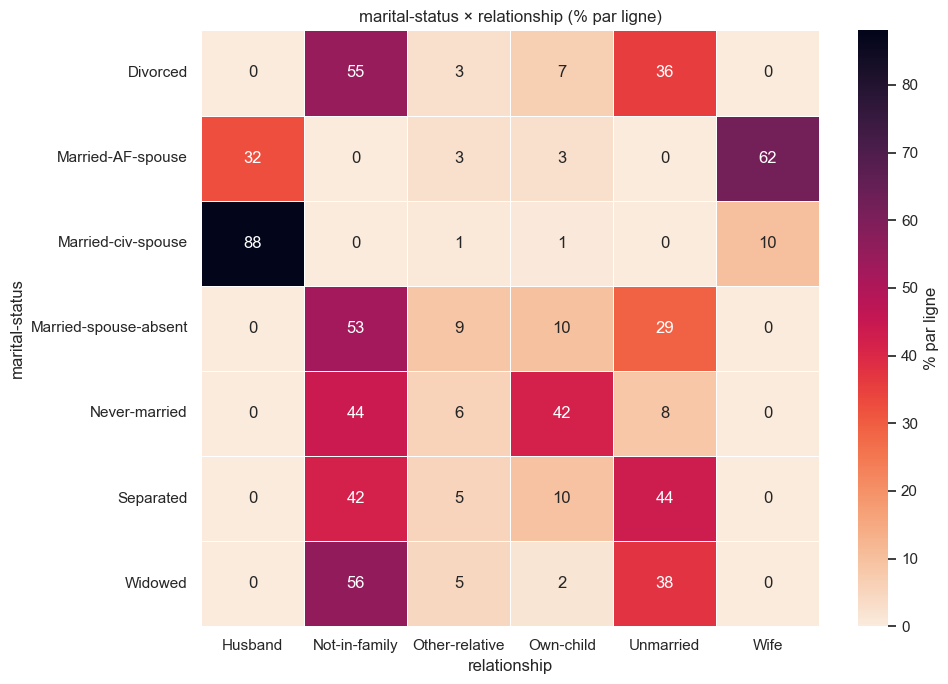

In [36]:
eda.plot_categorical_crosstab("marital-status", "relationship");

Ce graphique se lit par lignes puis colonnes : par exemple, 88% des married-civ-spouse (`marital-status`) sont des husband (`relationship`). On se demande donc pour chaque ligne "pour quelqu'un qui a ce status marital, quelle est sa relation ?"

`marital-status` et `relationship` sont fortement liées mais complémentaires (Cramer's V environ = 0,49). L'axe "marié/pas marié" est redondant (Married-* ⇒ Husband/Wife). Pour les statuts sans conjoint (Divorced, Never-married, Separated, Widowed), Husband/Wife = 0 %, et relationship les répartit différemment (Not-in-family, Unmarried, Own-child). Cette répartition, notamment le partage Never-married entre Not-in-family et Own-child, est une information de rôle dans le ménage que marital-status ne capte pas. C'est ce qui empêche le Cramer's V d'atteindre 1.

Malgré ce lien, on fait le choix de garder ces deux variables.

#### 7.2.2. `sex` et `relationship`

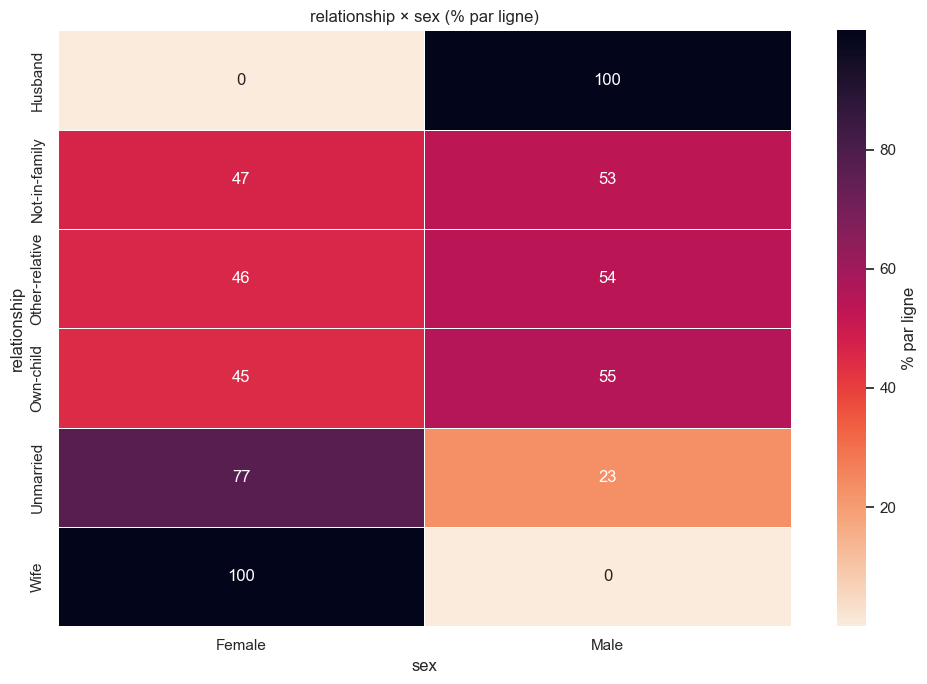

In [37]:
eda.plot_categorical_crosstab("relationship", "sex");

Ici le cramer's V est élevé (0.65) car les modalités wife, husband et unmarried ont beaucoup de poids (nombre d'individus et/ou déterminisme (100/0 pour wife par ex malgré un peu plus de 2000 individus "seulement")), qui pour lesquels l'information donnée par les deux variables est complètement redondante (pour wife et husband) et en grande partie pour unmarried. De ce fait, le cramer's V gonfle. Cependant, comme on a des modalités ou c'est proche du 50/50, cela signifie qu'on ne peut pas considérer une des deux variables comme à supprimer.

Si on avait eu quelque chose de scindé du type :  
0/100
100/0
100/
0/100
...

on aurait pu garder `sex` car plus simple OU préférer garder la granularité liée au fait d'avoir plus de modalité donc choisir `relationship` OU alors garder la variable pour laquelle le cramer's V est le plus elevé **avec la cible**.

#### 7.2.3. `workclass` et `occupation`

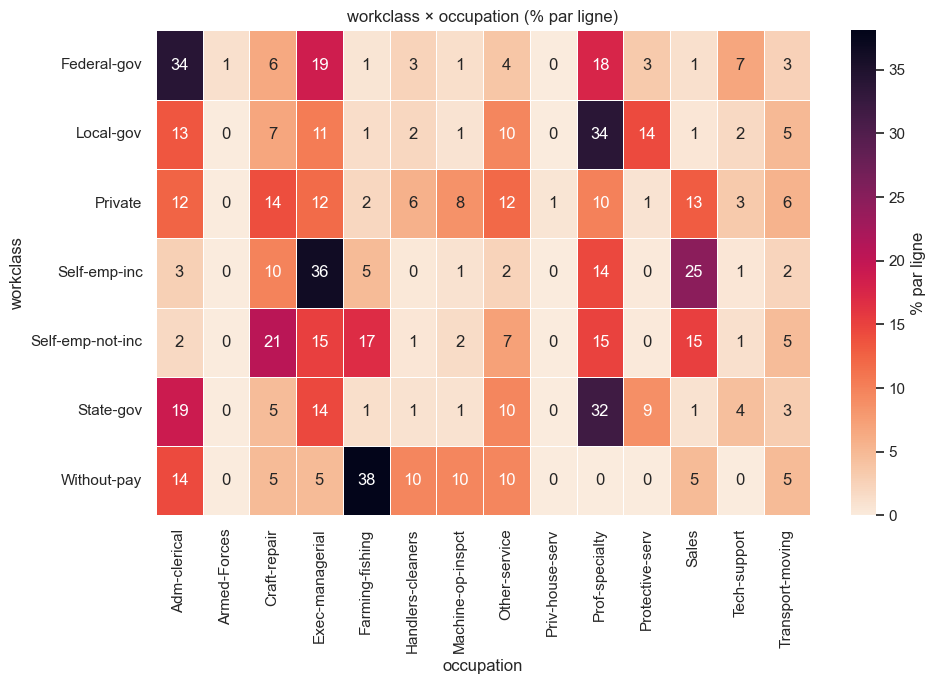

In [43]:
eda.plot_categorical_crosstab("workclass", "occupation");

globalment, avec le cramer's on a un df = 6 donc en gros 0.22 avec df = 6 c'est pas mal niveau associationen fait, mais l'association est pas assez forte (à creuser, j'ai du mal à comprendre le cramers V par moment)

## 8 Tests d'hypothèses

### 8.1 Tests d'indépendance entre `income` `fnlwgt`

Afin de tenter de vérifier si `fnlwgt` est vraiment inutile pour la modélisation, on tente en premier lieu un chi2 de contingence (nécessite un binning pour du qualitatif/quantitatif)

In [41]:
eda.chi2_numeric_target("fnlwgt")

,chi2,p_value,dof,cramers_v,n_bins
feature,,,,,
fnlwgt,49.595303,1.283397e-07,9,0.02883,10


Ici, la p-value du test est inférieure à 0.05, donc on rejette l'hypothèse d'indépendance. Pour autant, il est important de prendre en compte le fait qu'on a beaucoup de données, ce qui fait qu'il est beaucoup plus difficile de conserver $H_0$ à cause de la puissance statistique : avec beaucoup de données, le test a une grande puissance et chaque différence devient significative, donc on rejette très facilement. De plus, bien que ce test soit présenté dans le cours, il n'est pas le meilleur test pour faire du qualitatif/quantitatif.

Un test plus efficace est le test de Mann Whitney.

In [42]:
eda.mann_whitney_target("fnlwgt")

,U,p_value,rank_biserial,median_pos,median_neg
feature,,,,,
fnlwgt,215371681.5,0.189691,-0.008031,176729.0,178811.0


Ici en revanche, la p-value du test est supérieure à 0.05, donc on ne rejette pas $H_0$ et par conséquent on ne rejette pas l'hypothèse d'indépendance.

Si on prend en compte les observations précédentes et ces tests d'hypothèses, il parait alors cohérent de supprimer cette variable de notre dataset pour simplifier la modélisation.

**--> rajouter plus de tests pour montrer les hypothèses ??? (y a pas mal de choses que j'observe mais sur les quelles je test pas ou j'ai psa de valeurs précises qui dit si oui ou non mon observation est vraie)**

## 9. Bilan de l'AED

Suite à l'AED, on peut faire un bilan des mesures à prendre dans le preprocessing pour faciliter le travail des modèles : 

Supressions de features : 

- `fnlwgt` : variable sans impact dans la détermination de la cible
- `education` : redondante avec `education-num` (même information, l'une est déjà encodée ordinalement, l'autre non)

Préprocessings spécifiques sur les features : 
- `capital-loss` : encodage binaire `has-capital-loss` car la distribution est très centrée autour d'un valeur, sans trop d'outliers extrêmes
- `capital-gain` : passage au log (réduire l'écart avec les outliers extrêmes) pour conserver l'information contrairement à `capital-loss` car un fort `capital-gain` est très significatif selon nos observations, la binarisation est également possible en plus pour aider certains modèles (type SVM).
- `native-country` : remplacer les manquants par la modalité la plus fréquente (US --> taux des missing très similaire) + regrouper les modalités concernant moins de 50 échantillons dans une modalité "Other" (ou procéder à un targetencoding, mais risque de data leakage)
- `workclass` : création d'une modalité "Unknown" pour représenter les valeurs manquantes (plutôt qu'une imputation, car ces modalités apportent une information différente de celle qu'on a avec la modalité la plus fréquente) 
- `occupation` : création d'une modalité "Unknown", même raisonnement que pour `workclass`

Autres mesures : 
- classe déséquilibrées (ratio (<=50k) 3:1 (>50k) environ) : utilisation de métriques spéficiques (PR AUC, Precision, Recall, F1, ...) + splits stratifiés

## 11. Importance des variables (information mutuelle)

à voir si on garde

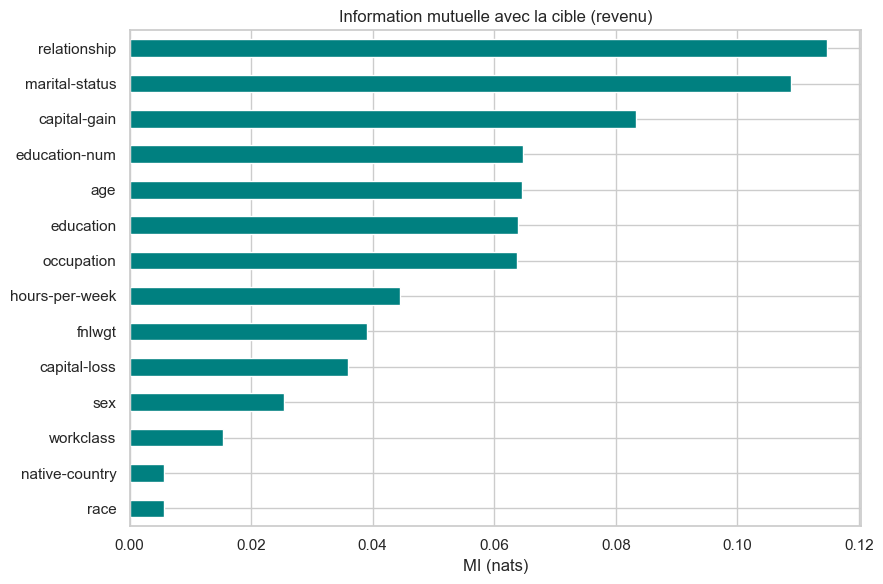

,mutual_info
relationship,0.114663
marital-status,0.108826
capital-gain,0.083236
education-num,0.064658
age,0.064549
education,0.063819
occupation,0.063672
hours-per-week,0.044528
fnlwgt,0.039022
capital-loss,0.036009


In [40]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

X_mi = X.copy()
for col in CATEGORICAL_FEATURES:
    X_mi[col] = LabelEncoder().fit_transform(X_mi[col].astype(str))

y_enc = (y == POSITIVE_CLASS).astype(int)
discrete_mask = [c in CATEGORICAL_FEATURES for c in X_mi.columns]

mi = mutual_info_classif(X_mi, y_enc, discrete_features=discrete_mask, random_state=42)
mi_s = pd.Series(mi, index=X_mi.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
mi_s.plot(kind="barh", color="teal", ax=ax)
ax.invert_yaxis()
ax.set_title("Information mutuelle avec la cible (revenu)")
ax.set_xlabel("MI (nats)")
fig.tight_layout()
plt.show()
mi_s.to_frame("mutual_info")


L'information mutuelle mesure la dépendance (linéaire ou non) entre chaque variable et la cible — plus c'est haut, plus la variable est informative, sans présumer du modèle.
On retrouve en tête les variables identifiés comme significative plus tôt : `marital-status`, `relationship`, `education-num`,
  `capital-gain`, `age`, `hours-per-week`
Et on retrouve en bas `fnlwgt`, `race`, `native-country` qu'on avait identifié comme peu significative.
On doit ensuite prioriser le feature engineering sur les variables fortes et envisager d'écarter celles proches de 0 (ex. `fnlwgt`).



## 12. Synthèse & implications pour la modélisation

| Constat EDA | Décision modélisation |
|---|---|
| Classes déséquilibrées (~24 % `>50K`) | Métriques ROC-AUC/F1, split stratifié, `class_weight`/seuil |
| Manquants codés `'?'` (workclass, occupation, native-country) | Imputer ou catégorie « Unknown » dédiée |
| `capital-gain/loss` très asymétriques, pleins de 0 | log1p / binarisation ; scaler robuste |
| `fnlwgt` peu informatif (MI ≈ 0) | Candidat à la suppression |
| `education` ≈ `education-num` (redondance) | Garder une seule des deux |
| Catégorielles à forte cardinalité (`native-country`) | Regrouper modalités rares / target-encoding |
| Variables très prédictives : `marital-status`, `relationship`, `education`, `occupation`, `capital-gain`, `age`, `hours-per-week` | Cœur du modèle, soigner leur encodage |
| Écart de taux selon `sex`/`race` | Surveiller le biais / fairness |